# DAPI–BigBrain-MR: 후보 검색, 영역 배정 및 DEG

`scrna` 커널에서 위에서 아래로 실행합니다. DAPI와 좌표를 준비하고, BigBrain-MR의 400 µm 조직 영상에서 후보를 검색한 뒤 100 µm 라벨로 확인합니다. 세포 밀도 hotspot으로 재정렬한 후보의 기존 voting·ensemble 및 DEG는 비교용입니다. 마지막 단계에서는 지역별 마커 기준을 통과한 후보만 최종 voting과 F1 가중 ensemble에 사용합니다.

입력 경로와 결과 저장 경로는 첫 코드 셀에서 설정합니다. 후보 검색은 수 분과 공개 atlas 다운로드가 필요합니다. 기존 결과 파일을 덮어쓰므로 필요하면 먼저 별도 폴더에 보관하세요. 저장된 출력은 기존 결과를 보존하기 위해 임시 폴더에서 수행한 검증 실행의 결과입니다.

이 지도는 Allen CCF가 아닙니다. [BigBrain-MR](https://zenodo.org/records/7432527), [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). 영상 유사도, F1 및 투표 지지율은 정합 정확도나 확률이 아닙니다. 영역 배정은 독립적인 해부학적 검증이 필요한 탐색적 결과입니다.

## 1. 데이터 및 DAPI 좌표 준비

In [1]:
# 세포 밀도 및 유사도 파라미터
CELL_DENSITY_BIN_UM = 50  # 밀도를 계산하는 구역 크기 (µm)
LOW_DENSITY_CELL_COUNT_MAX = 2  # 구역당 세포가 이 값 이하면 저밀도
HIGH_DENSITY_CELL_COUNT_MIN = 6  # 구역당 세포가 이 값 이상이면 고밀도
LOW_DENSITY_SCORE_BOOST = 1.0  # 저밀도 가중치: 최대 1 + 이 값
HIGH_DENSITY_SCORE_BOOST = 2.0  # 고밀도 가중치: 최대 1 + 이 값

# 찢김 및 atlas 경계 파라미터
TEAR_DARK_PERCENTILE = 10
TEAR_CELL_COUNT_MAX = 10
TEAR_NEIGHBOR_EXPECTED_MIN = 2
TEAR_MIN_COMPONENT_BINS = 2
TEAR_TEMPLATE_COVERAGE_MIN = 0.5
MAX_OUTSIDE_CELL_FRACTION = 0.05  # Reject when at least 5% of cells fall outside atlas tissue.
MRI_DARK_INTENSITY_MAX = 0.10  # MRI 표시 밝기 0~1 중 이 값 이하는 검은색

from pathlib import Path
import gzip
import json

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import requests
import scanpy as sc
import tifffile

DATA_DIR = Path('/home/Data_Drive_8TB/kykim/CCF_annotation')
OUTPUT_DIR = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/CCF')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
adata = sc.read_h5ad(DATA_DIR / 'adata.h5ad')
with (DATA_DIR / 'manifest.json').open() as f:
    manifest = json.load(f)
micron_to_mosaic = np.loadtxt(DATA_DIR / 'micron_to_mosaic_pixel_transform.csv')
dapi = tifffile.imread(DATA_DIR / 'mosaic_DAPI_z0_downsampled.tif')

print(adata)
print('DAPI shape:', dapi.shape, dapi.dtype)
print('micron-to-original-pixel transform:\n', micron_to_mosaic)

<tifffile.TiffFile 'mosaic_DAPI_z0_downsampled.tif'> shaped series shape does not match page shape


AnnData object with n_obs × n_vars = 137627 × 1000
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'Anti-Rb-APP_raw', 'Anti-Rb-APP_high_pass', 'Anti-Ms-pTau_raw', 'Anti-Ms-pTau_high_pass', 'PolyT_raw', 'PolyT_high_pass', 'DAPI_raw', 'DAPI_high_pass'
    obsm: 'spatial'
DAPI shape: (8032, 11943) uint16
micron-to-original-pixel transform:
 [[  9.25930309   0.         318.04150391]
 [  0.           9.25934219 486.28436279]
 [  0.           0.           1.        ]]


In [2]:
if dapi.ndim != 2 or micron_to_mosaic.shape != (3, 3):
    raise ValueError('Expected a 2D DAPI image and a 3x3 coordinate transform.')
if not np.allclose(micron_to_mosaic[2], [0, 0, 1]):
    raise ValueError('Expected an affine transform in homogeneous coordinates.')

full_width = manifest['mosaic_width_pixels']
full_height = manifest['mosaic_height_pixels']
height, width = dapi.shape
um_per_pixel = manifest['microns_per_pixel']
width_mm = full_width * um_per_pixel / 1000
height_mm = full_height * um_per_pixel / 1000
dapi_extent = (-width_mm / 2, width_mm / 2, -height_mm / 2, height_mm / 2)

xy_um = adata.obs[['center_x', 'center_y']].to_numpy(dtype=float)
xy_original = (np.c_[xy_um, np.ones(len(xy_um))] @ micron_to_mosaic.T)[:, :2]
xy_downsampled = (xy_original + 0.5) * [width / full_width, height / full_height] - 0.5
xy_mm = np.column_stack(((xy_original[:, 0] + 0.5) * um_per_pixel / 1000 - width_mm / 2,
                         height_mm / 2 - (xy_original[:, 1] + 0.5) * um_per_pixel / 1000))
inside = (np.isfinite(xy_downsampled).all(axis=1)
          & (xy_downsampled[:, 0] >= -0.5) & (xy_downsampled[:, 0] < width - 0.5)
          & (xy_downsampled[:, 1] >= -0.5) & (xy_downsampled[:, 1] < height - 0.5))
if not inside.all():
    raise ValueError(f'{(~inside).sum():,} cell coordinates are outside the DAPI image or non-finite.')

adata.obsm['dapi_downsampled_pixel'] = xy_downsampled
adata.obsm['dapi_centered_mm'] = xy_mm
vmax = np.percentile(dapi[::10, ::10], 99.5)
print(f'DAPI physical size: {width_mm:.3f} x {height_mm:.3f} mm')
print(f'Downsample ratios x/y: {full_width / width:.5f}, {full_height / height:.5f}')
print(f'Cells within DAPI: {inside.sum():,} / {adata.n_obs:,}')

DAPI physical size: 12.899 x 8.674 mm
Downsample ratios x/y: 10.00008, 9.99988
Cells within DAPI: 137,627 / 137,627


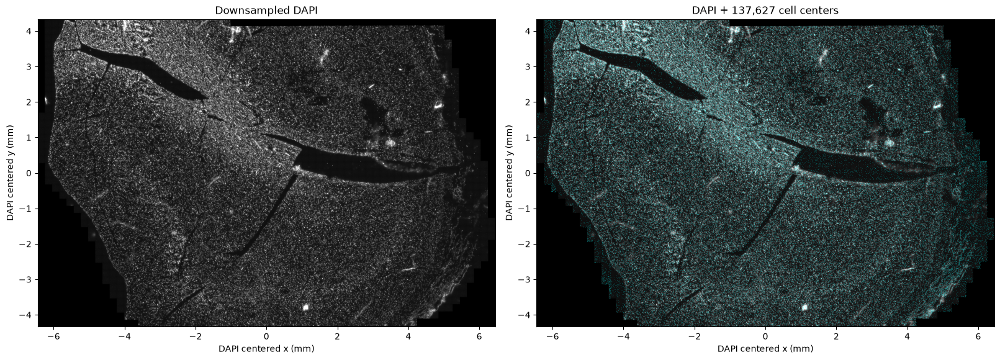

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
for ax in axes:
    ax.imshow(dapi, cmap='gray', origin='upper', extent=dapi_extent, vmin=0, vmax=vmax)
    ax.set_aspect('equal')
    ax.set_xlabel('DAPI centered x (mm)')
    ax.set_ylabel('DAPI centered y (mm)')
axes[0].set_title('Downsampled DAPI')
axes[1].scatter(xy_mm[:, 0], xy_mm[:, 1], s=0.15, c='cyan', alpha=0.35, linewidths=0, rasterized=True)
axes[1].set_title(f'DAPI + {adata.n_obs:,} cell centers')
plt.show()

In [3]:
import cv2
import ipywidgets as widgets
from IPython.display import display
from matplotlib.transforms import Affine2D
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu

display_um = 20
display_width = round(width_mm * 1000 / display_um)
display_height = round(height_mm * 1000 / display_um)
dapi_small = cv2.resize(dapi, (display_width, display_height), interpolation=cv2.INTER_AREA)
dapi_smooth = ndi.gaussian_filter(dapi_small.astype(float), sigma=2)
tissue_mask = dapi_smooth > threshold_otsu(dapi_smooth)
tissue_mask = ndi.binary_fill_holes(ndi.binary_closing(tissue_mask, iterations=4))
labels, _ = ndi.label(tissue_mask)
component_sizes = np.bincount(labels.ravel())
keep = component_sizes >= 0.001 * tissue_mask.size
keep[0] = False
tissue_mask = keep[labels]
low, high = np.percentile(dapi_small, [1, 99.8])
if high <= low or not tissue_mask.any():
    raise ValueError('DAPI intensity range or estimated tissue mask is invalid.')
dapi_8bit = np.uint8(np.clip((dapi_small.astype(float) - low) * 255 / (high - low), 0, 255))
dapi_enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(dapi_8bit)
edge_x = np.linspace(dapi_extent[0] + width_mm / (2 * display_width),
                     dapi_extent[1] - width_mm / (2 * display_width), display_width)
edge_y = np.linspace(dapi_extent[3] - height_mm / (2 * display_height),
                     dapi_extent[2] + height_mm / (2 * display_height), display_height)
cell_col = np.clip(((xy_original[:, 0] + 0.5) * display_width / full_width).astype(int), 0, display_width - 1)
cell_row = np.clip(((xy_original[:, 1] + 0.5) * display_height / full_height).astype(int), 0, display_height - 1)
print(f'Estimated tissue mask contains {tissue_mask[cell_row, cell_col].mean():.1%} of cell centers; inspect boundary before use.')
print(f'Enhanced DAPI display pixel size: {width_mm * 1000 / display_width:.2f} x {height_mm * 1000 / display_height:.2f} µm')

Estimated tissue mask contains 90.3% of cell centers; inspect boundary before use.
Enhanced DAPI display pixel size: 20.00 x 19.99 µm


## BigBrain-MR 공간에서 DAPI 후보 검색

BigBrain-MR 조직 영상과 20개 ROI 지도는 동일 공간에 정렬되어 있습니다. 슬라이드의 크기를 mm로 유지하고 400 µm 조직 영상에서 모든 coronal 단면과 0–355°의 72개 회전을 검색합니다. 선택된 후보는 100 µm 라벨로 확인하지만, 검색 위치 자체가 100 µm 정밀도로 최적화되는 것은 아닙니다. 높은 해상도와 정합 정확도는 다릅니다.

기존 찢김·저밀도 겹침 제외와 밀도 가중치를 유지합니다. 세포가 배경 또는 뇌척수액(label 3)에 5% 이상 놓인 후보는 제외하며, 최종 후보는 100 µm 라벨로 다시 검사합니다. 고밀도와 검은 MRI의 겹침은 같은 공간의 **합성 T1 영상**에서 `MRI_DARK_INTENSITY_MAX` 이하를 검은색으로 하여 400 µm 검색 격자에서 제외합니다. 합성 T1은 실제 측정 MRI가 아닙니다. 50 µm 고밀도 구역의 일부라도 포함하는 400 µm 격자를 고밀도로 취급하고 회전 시 보수적으로 포함하므로 경계에서 더 넓게 검사할 수 있습니다. 좌우 반전은 검색하지 않습니다. 영상 및 라벨 모두 다른 사람의 뇌에 기반하므로 후보는 검증된 해부학적 정합이 아닙니다.

In [4]:
import gzip
import math
import time
import nibabel as nib
import pandas as pd

# BigBrain-MR aligned 400 µm histology, label map and synthetic T1.
bigbrain_base = 'https://zenodo.org/records/7432527/files/'
def load_bigbrain_volume(filename):
    response = requests.get(bigbrain_base + filename, timeout=(30, 600))
    response.raise_for_status()
    return nib.Nifti1Image.from_bytes(gzip.decompress(response.content))

histo_image = load_bigbrain_volume('BigBrainMR_Histo_400um.nii.gz')
coarse_label_image = load_bigbrain_volume('BigBrainMR_Labels_400um.nii.gz')
t1_image = load_bigbrain_volume('BigBrainMR_T1weighted_400um.nii.gz')
voxel_mm = 0.4
for image in (histo_image, coarse_label_image, t1_image):
    if image.shape != histo_image.shape or not np.allclose(image.affine, histo_image.affine):
        raise ValueError('BigBrain-MR 400 µm images do not share the same grid.')
if not np.allclose(histo_image.affine[:3, :3], np.eye(3) * voxel_mm):
    raise ValueError('Unexpected BigBrain-MR 400 µm orientation or spacing.')
volume_affine = histo_image.affine.copy()
coarse_labels = np.asanyarray(coarse_label_image.dataobj)
if not set(np.unique(coarse_labels)).issubset(set(range(21))):
    raise ValueError('Unknown BigBrain-MR label.')
atlas_mask_volume = (coarse_labels > 0) & (coarse_labels != 3)
atlas_volume = np.asanyarray(histo_image.dataobj)
t1_raw = np.asanyarray(t1_image.dataobj)
t1_low, t1_high = np.percentile(t1_raw[atlas_mask_volume], [1, 99])
if t1_high <= t1_low or not atlas_mask_volume.any():
    raise ValueError('Invalid synthetic T1 intensity range or tissue mask.')
atlas_t1_volume = np.clip((t1_raw.astype(np.float32) - t1_low) / (t1_high - t1_low), 0, 1)
atlas_t1_volume *= 65534
atlas_t1_volume[~atlas_mask_volume] = 65535
atlas_nx, atlas_ny, atlas_nz = atlas_volume.shape
volume_extent = (volume_affine[0, 3] - voxel_mm / 2,
                 volume_affine[0, 3] + (atlas_nx - 0.5) * voxel_mm,
                 volume_affine[2, 3] - voxel_mm / 2,
                 volume_affine[2, 3] + (atlas_nz - 0.5) * voxel_mm)
print(f'BigBrain-MR histology / synthetic T1 / labels: {atlas_volume.shape} at {voxel_mm:g} mm')
print('Brain tissue is defined as label 1–20 except CSF (3); T1 is a synthetic MRI contrast.')

template_w = math.ceil(width_mm / voxel_mm)
template_h = math.ceil(height_mm / voxel_mm)
template_x = (np.arange(template_w, dtype=np.float32) - (template_w - 1) / 2) * voxel_mm
template_y = ((template_h - 1) / 2 - np.arange(template_h, dtype=np.float32)) * voxel_mm
map_x, map_y = np.meshgrid((template_x + width_mm / 2) * display_width / width_mm - 0.5,
                           (height_mm / 2 - template_y) * display_height / height_mm - 0.5)
antialias_sigma_x = voxel_mm * 1000 / (2.355 * (width_mm * 1000 / display_width))
antialias_sigma_y = voxel_mm * 1000 / (2.355 * (height_mm * 1000 / display_height))
template_intensity = cv2.GaussianBlur(dapi_8bit.astype(np.float32) / 255, (0, 0),
                                      sigmaX=antialias_sigma_x, sigmaY=antialias_sigma_y)
template_intensity = cv2.remap(template_intensity, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)

# Flag contiguous, unusually dark gaps only where neighboring tissue has cells.
tear_bin_um = CELL_DENSITY_BIN_UM
dapi_pixel_um = width_mm * 1000 / width
tear_bin_pixels = max(1, round(tear_bin_um / dapi_pixel_um))
tear_grid_w = math.ceil(width / tear_bin_pixels)
tear_grid_h = math.ceil(height / tear_bin_pixels)
cell_pixel_x = (xy_original[:, 0] + 0.5) * width / full_width - 0.5
cell_pixel_y = (xy_original[:, 1] + 0.5) * height / full_height - 0.5
cell_count_grid, _, _ = np.histogram2d(
    cell_pixel_y, cell_pixel_x,
    bins=(tear_grid_h, tear_grid_w),
    range=((0, tear_grid_h * tear_bin_pixels), (0, tear_grid_w * tear_bin_pixels)),
)
cell_grid_x = np.clip((cell_pixel_x / tear_bin_pixels).astype(int), 0, tear_grid_w - 1)
cell_grid_y = np.clip((cell_pixel_y / tear_bin_pixels).astype(int), 0, tear_grid_h - 1)
cell_grid_points = np.unique(np.column_stack((cell_grid_x, cell_grid_y)), axis=0).astype(np.int32)
slide_hull_grid = cv2.convexHull(cell_grid_points)
slide_boundary_grid = np.zeros((tear_grid_h, tear_grid_w), dtype=np.uint8)
cv2.fillConvexPoly(slide_boundary_grid, slide_hull_grid, 1)
slide_boundary_display = np.zeros((display_height, display_width), dtype=np.uint8)
slide_hull_display = cv2.convexHull(
    np.column_stack((cell_col, cell_row)).astype(np.int32)
)
slide_boundary_display[:] = 0
cv2.fillConvexPoly(slide_boundary_display, slide_hull_display, 1)
slide_boundary_fraction = cv2.GaussianBlur(
    slide_boundary_display.astype(np.float32), (0, 0),
    sigmaX=antialias_sigma_x, sigmaY=antialias_sigma_y,
)
slide_boundary_fraction = cv2.remap(
    slide_boundary_fraction, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT
)
slide_boundary_template = (slide_boundary_fraction >= 0.5).astype(np.uint8)
dapi_mean_grid = cv2.resize(dapi, (tear_grid_w, tear_grid_h), interpolation=cv2.INTER_AREA).astype(np.float32)
local_expected_cells = np.maximum(
    ndi.median_filter(cell_count_grid, size=7, mode='nearest'),
    ndi.gaussian_filter(cell_count_grid, sigma=2),
)
occupied_dapi = dapi_mean_grid[cell_count_grid > 0]
if occupied_dapi.size == 0:
    raise ValueError('No detected cells are available for tissue-tear screening.')
dark_gap_limit = np.percentile(occupied_dapi, TEAR_DARK_PERCENTILE)
inside_boundary_core = slide_boundary_grid.astype(bool) & ~ndi.binary_dilation(~slide_boundary_grid.astype(bool))
low_density_grid = (cell_count_grid <= LOW_DENSITY_CELL_COUNT_MAX) & inside_boundary_core
tear_seed = ((cell_count_grid <= TEAR_CELL_COUNT_MAX)
             & (local_expected_cells >= TEAR_NEIGHBOR_EXPECTED_MIN)
             & (dapi_mean_grid < dark_gap_limit) & inside_boundary_core)
tear_labels, _ = ndi.label(tear_seed, structure=np.ones((3, 3), dtype=bool))
tear_sizes = np.bincount(tear_labels.ravel())
keep_tear_component = tear_sizes >= TEAR_MIN_COMPONENT_BINS
keep_tear_component[0] = False
tear_mask_100um = keep_tear_component[tear_labels]
tear_fraction_template = cv2.resize(
    tear_mask_100um.astype(np.float32), (template_w, template_h), interpolation=cv2.INTER_AREA
)
tear_low_density_overlap = tear_mask_100um & low_density_grid
overlap_fraction_template = cv2.resize(
    tear_low_density_overlap.astype(np.float32), (template_w, template_h), interpolation=cv2.INTER_AREA
)
coverage_exclusion_template = tear_fraction_template >= TEAR_TEMPLATE_COVERAGE_MIN
overlap_exclusion_template = overlap_fraction_template > 0
tear_exclusion_template = coverage_exclusion_template | overlap_exclusion_template
template_support = ((slide_boundary_template > 0) & ~tear_exclusion_template).astype(np.uint8)
low_density_fraction_template = cv2.resize(
    (low_density_grid & ~tear_mask_100um).astype(np.float32),
    (template_w, template_h), interpolation=cv2.INTER_AREA
)
if HIGH_DENSITY_CELL_COUNT_MIN <= LOW_DENSITY_CELL_COUNT_MAX:
    raise ValueError('High-density minimum must be greater than the low-density maximum.')
high_density_grid = ((cell_count_grid >= HIGH_DENSITY_CELL_COUNT_MIN)
                     & inside_boundary_core & ~tear_mask_100um)
high_density_fraction_template = cv2.resize(
    high_density_grid.astype(np.float32), (template_w, template_h), interpolation=cv2.INTER_AREA
)
high_density_valid_template = (high_density_fraction_template > 0) & template_support.astype(bool)
if not 0 <= MRI_DARK_INTENSITY_MAX < 1:
    raise ValueError("MRI_DARK_INTENSITY_MAX must be in [0, 1).")
if not high_density_valid_template.any():
    raise ValueError("No valid high-density template pixels remain after tear exclusion.")
density_weight_template = template_support.astype(np.float32) * (
    1.0 + LOW_DENSITY_SCORE_BOOST * low_density_fraction_template
    + HIGH_DENSITY_SCORE_BOOST * high_density_fraction_template
)
tear_mask_display = cv2.resize(
    tear_mask_100um.astype(np.uint8), (display_width, display_height), interpolation=cv2.INTER_NEAREST
)
low_density_display = cv2.resize(
    (low_density_grid & ~tear_mask_100um).astype(np.uint8),
    (display_width, display_height), interpolation=cv2.INTER_NEAREST
)
high_density_display = cv2.resize(
    high_density_grid.astype(np.uint8), (display_width, display_height), interpolation=cv2.INTER_NEAREST
)
print(f'DAPI low-signal cutoff: {TEAR_DARK_PERCENTILE}th percentile = {dark_gap_limit:.2f}')
print(f'Low-density weighting: <= {LOW_DENSITY_CELL_COUNT_MAX:g} cells / {CELL_DENSITY_BIN_UM:g} µm bin; '
      f'weight boost {LOW_DENSITY_SCORE_BOOST:g} (maximum weight '
      f'{1 + LOW_DENSITY_SCORE_BOOST:g}x)')
print(f'High-density weighting: >= {HIGH_DENSITY_CELL_COUNT_MIN:g} cells / {CELL_DENSITY_BIN_UM:g} µm bin; '
      f'maximum weight {1 + HIGH_DENSITY_SCORE_BOOST:g}x')
print(f'Tear candidates: {tear_mask_100um.sum()} {CELL_DENSITY_BIN_UM:g} µm bins; '
      f'{int(tear_exclusion_template.sum())} 400 µm template pixels excluded.')
print(f'Tear/low-density overlap: {int(tear_low_density_overlap.sum())} bins; '
      f'{int((overlap_exclusion_template & ~coverage_exclusion_template).sum())} '
      f'additional 400 µm pixels excluded regardless of coverage cutoff.')
print(f'Slide outer boundary: convex hull of {len(cell_grid_points):,} occupied {CELL_DENSITY_BIN_UM} µm cell bins; '
      f'{int(slide_boundary_template.sum())} / {template_w * template_h} atlas-scale pixels included.')

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
ax.imshow(dapi, cmap='gray', origin='upper', extent=dapi_extent, vmin=0,
          vmax=np.percentile(dapi[::16, ::16], 99.5))
ax.imshow(np.ma.masked_where(~(low_density_grid & ~tear_mask_100um), low_density_grid), cmap='Blues', origin='upper', extent=dapi_extent,
          alpha=0.45, vmin=0, vmax=1, interpolation='nearest')
ax.imshow(tear_mask_100um.astype(float), cmap='Reds', origin='upper', extent=dapi_extent,
          alpha=0.7 * tear_mask_100um.astype(float), vmin=0, vmax=1, interpolation='nearest')
ax.contour(edge_x, edge_y, slide_boundary_display.astype(float), levels=[0.5], colors='lime', linewidths=1)
ax.set_aspect('equal')
ax.set_title('Green: slide boundary; blue: low density; red: tear candidates (overlap excluded)')
ax.set_xlabel('DAPI x (mm)')
ax.set_ylabel('DAPI y (mm)')
plt.show()
def internal_intensity_pattern(image, support):
    support = support.astype(np.float32)
    weighted = image.astype(np.float32) * support
    scales = []
    for sigma in (0.4 / voxel_mm, 1.6 / voxel_mm):
        weights = cv2.GaussianBlur(support, (0, 0), sigma)
        blurred = cv2.GaussianBlur(weighted, (0, 0), sigma)
        scales.append(np.divide(blurred, weights, out=np.zeros_like(blurred), where=weights > 1e-4))
    return scales[0] - scales[1]

template_pattern = internal_intensity_pattern(template_intensity, template_support)
if template_support.sum() < 30 or np.std(template_pattern[template_support.astype(bool)]) < 0.003:
    raise ValueError('Not enough informative internal DAPI pixels for 400 µm pattern matching.')
print(f'Atlas volume: {atlas_volume.shape}; {atlas_ny} coronal sections at {voxel_mm} mm spacing')
print(f'DAPI template: {template_w} x {template_h} pixels; slide-boundary pixels after tear correction: {template_support.sum()}')

BigBrain-MR histology / synthetic T1 / labels: (388, 480, 408) at 0.4 mm
Brain tissue is defined as label 1–20 except CSF (3); T1 is a synthetic MRI contrast.


DAPI low-signal cutoff: 10th percentile = 1964.00
Low-density weighting: <= 2 cells / 50 µm bin; weight boost 1 (maximum weight 2x)
High-density weighting: >= 6 cells / 50 µm bin; maximum weight 3x
Tear candidates: 3016 50 µm bins; 288 400 µm template pixels excluded.
Tear/low-density overlap: 2037 bins; 263 additional 400 µm pixels excluded regardless of coverage cutoff.
Slide outer boundary: convex hull of 37,435 occupied 50 µm cell bins; 643 / 726 atlas-scale pixels included.
Atlas volume: (388, 480, 408); 480 coronal sections at 0.4 mm spacing
DAPI template: 33 x 22 pixels; slide-boundary pixels after tear correction: 371


In [5]:
def make_rotated_templates(pattern, mask, weights, high_density, cell_xy_mm, voxel_mm):
    h, w = pattern.shape
    side = math.ceil(math.hypot(w, h)) + 4
    if side % 2 == 0:
        side += 1
    pad = side // 2
    center = np.float32([[1, 0, pad - (w - 1) / 2], [0, 1, pad - (h - 1) / 2]])
    canvas = cv2.warpAffine(pattern, center, (side, side), flags=cv2.INTER_LINEAR)
    mask_canvas = cv2.warpAffine(mask, center, (side, side), flags=cv2.INTER_NEAREST)
    weights_canvas = cv2.warpAffine(weights.astype(np.float32), center, (side, side), flags=cv2.INTER_LINEAR)
    high_canvas = cv2.warpAffine(high_density.astype(np.float32), center, (side, side), flags=cv2.INTER_LINEAR)
    cell_points = np.column_stack((cell_xy_mm[:, 0] / voxel_mm + pad,
                                   -cell_xy_mm[:, 1] / voxel_mm + pad))
    result = []
    for angle in range(0, 360, 5):
        rotation = cv2.getRotationMatrix2D((pad, pad), angle, 1)
        rotated = cv2.warpAffine(canvas, rotation, (side, side), flags=cv2.INTER_LINEAR)
        rotated_mask = cv2.warpAffine(mask_canvas, rotation, (side, side), flags=cv2.INTER_NEAREST)
        rotated_weights = cv2.warpAffine(weights_canvas, rotation, (side, side), flags=cv2.INTER_LINEAR)
        rotated_weights *= rotated_mask
        rotated_high = (cv2.warpAffine(high_canvas, rotation, (side, side),
                                       flags=cv2.INTER_LINEAR) > 0) & (rotated_mask > 0)
        if not rotated_high.any():
            raise ValueError(f"No high-density pixels remain at angle {angle}.")
        rotated_cells = cell_points @ rotation[:, :2].T + rotation[:, 2]
        cell_cols = np.floor(rotated_cells[:, 0] + 0.5).astype(int)
        cell_rows = np.floor(rotated_cells[:, 1] + 0.5).astype(int)
        if np.any((cell_cols < 0) | (cell_cols >= side) | (cell_rows < 0) | (cell_rows >= side)):
            raise ValueError(f'Rotated cell coordinates exceed the template at angle {angle}.')
        cell_counts = np.bincount(cell_rows * side + cell_cols, minlength=side * side).reshape(side, side).astype(np.float32)
        rows, cols = np.nonzero(rotated_mask)
        result.append((angle, rotated, rotated_mask, rotated_weights,
                       rows.min(), rows.max(), cols.min(), cols.max(), cell_counts, rotated_high.astype(np.float32)))
    return result

def compute_score_map(atlas_pattern, atlas_tissue, atlas_black, rotated_template, max_outside_cell_fraction, minimum_tissue=0.85):
    angle, pattern, mask, weights, row_min, row_max, col_min, col_max, cell_counts, high_density = rotated_template
    pad = pattern.shape[0] // 2
    image = cv2.copyMakeBorder(atlas_pattern, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
    tissue = cv2.copyMakeBorder(atlas_tissue.astype(np.float32), pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
    outside = 1.0 - tissue
    total_cells = float(cell_counts.sum())
    if total_cells <= 0 or not 0 < max_outside_cell_fraction <= 1:
        raise ValueError('Cell count and maximum outside-cell fraction must be positive.')
    outside_cells = np.clip(np.rint(cv2.matchTemplate(outside, cell_counts, cv2.TM_CCORR)), 0, total_cells)
    outside_fraction = outside_cells / total_cells
    black = cv2.copyMakeBorder(atlas_black.astype(np.float32), pad, pad, pad, pad,
                               cv2.BORDER_CONSTANT, value=0)
    black_high_overlap = np.clip(np.rint(cv2.matchTemplate(black, high_density, cv2.TM_CCORR)),
                                 0, high_density.sum())
    mask_float = mask.astype(np.float32)
    weights = weights.astype(np.float32)
    count = float(mask.sum())
    weight_sum = float(weights.sum())
    weighted_pattern = weights * pattern
    pattern_sum = float(weighted_pattern.sum())
    pattern_square_sum = float((weighted_pattern * pattern).sum())
    template_variance = max(pattern_square_sum - pattern_sum * pattern_sum / weight_sum, 0.0)
    target_sum = cv2.matchTemplate(image, weights, cv2.TM_CCORR)
    target_square_sum = cv2.matchTemplate(image * image, weights, cv2.TM_CCORR)
    cross_sum = cv2.matchTemplate(image, weighted_pattern, cv2.TM_CCORR)
    target_variance = np.maximum(target_square_sum - target_sum * target_sum / weight_sum, 0)
    covariance = cross_sum - pattern_sum * target_sum / weight_sum
    denominator = np.sqrt(template_variance * target_variance)
    scores = np.divide(covariance, denominator, out=np.full_like(covariance, -np.inf),
                       where=denominator > 1e-8)
    fraction = cv2.matchTemplate(tissue, mask_float, cv2.TM_CCORR) / count
    local_variance = target_variance / weight_sum
    valid = (np.isfinite(scores) & (np.abs(scores) <= 1.00001)
             & (fraction >= minimum_tissue)
             & (outside_cells < max_outside_cell_fraction * total_cells)
             & (black_high_overlap == 0)
             & (local_variance >= 0.003 ** 2)
             & (template_variance / weight_sum >= 0.003 ** 2))
    valid[:max(0, pad - row_min), :] = False
    valid[min(valid.shape[0], valid.shape[0] - (row_max - pad)):, :] = False
    valid[:, :max(0, pad - col_min)] = False
    valid[:, min(valid.shape[1], valid.shape[1] - (col_max - pad)):] = False
    scores[~valid] = -np.inf
    return scores, outside_fraction

def bin_maxima(score_map, bin_pixels):
    height, width = score_map.shape
    ny, nx = math.ceil(height / bin_pixels), math.ceil(width / bin_pixels)
    padded = np.pad(score_map, ((0, ny * bin_pixels - height), (0, nx * bin_pixels - width)), constant_values=-np.inf)
    blocks = padded.reshape(ny, bin_pixels, nx, bin_pixels).transpose(0, 2, 1, 3).reshape(ny, nx, -1)
    index = np.argmax(blocks, axis=2)
    values = np.take_along_axis(blocks, index[..., None], axis=2)[..., 0]
    rows = np.arange(ny)[:, None] * bin_pixels + index // bin_pixels
    cols = np.arange(nx)[None, :] * bin_pixels + index % bin_pixels
    return values, rows, cols

In [6]:
rotated_templates = make_rotated_templates(template_pattern, template_support, density_weight_template,
                                           high_density_valid_template, xy_mm, voxel_mm)
assert len(rotated_templates) == 72
bin_pixels = max(1, round(3.2 / voxel_mm))
slices_per_bin = max(1, round(2.0 / voxel_mm))
bins_shape = (math.ceil(atlas_ny / slices_per_bin), math.ceil(atlas_nz / bin_pixels), math.ceil(atlas_nx / bin_pixels))
best_score = np.full(bins_shape, -np.inf, dtype=np.float32)
best_outside_fraction = np.full(bins_shape, np.nan, dtype=np.float32)
best_slice = np.full(bins_shape, -1, dtype=np.int16)
best_angle = np.full(bins_shape, -1, dtype=np.int16)
best_row = np.full(bins_shape, -1, dtype=np.int16)
best_col = np.full(bins_shape, -1, dtype=np.int16)
old_cv_threads = cv2.getNumThreads()
started = time.perf_counter()
empty_sections = 0
cv2.setNumThreads(1)
try:
    for section in range(atlas_ny):
        atlas_image = atlas_volume[:, section, :].T[::-1, :]
        atlas_tissue = atlas_mask_volume[:, section, :].T[::-1, :]
        if atlas_tissue.sum() < 0.85 * min(t[2].sum() for t in rotated_templates):
            empty_sections += 1
            continue
        atlas_dark = 1 - np.clip(atlas_image / 65535.0, 0, 1)
        t1_slice = atlas_t1_volume[:, section, :].T[::-1, :]
        atlas_black = t1_slice <= MRI_DARK_INTENSITY_MAX * 65535.0
        atlas_pattern = internal_intensity_pattern(atlas_dark, atlas_tissue)
        zbin = section // slices_per_bin
        for rotated in rotated_templates:
            score_map, outside_fraction = compute_score_map(
                atlas_pattern, atlas_tissue, atlas_black, rotated, MAX_OUTSIDE_CELL_FRACTION
            )
            values, rows, cols = bin_maxima(score_map, bin_pixels)
            better = values > best_score[zbin]
            best_score[zbin][better] = values[better]
            best_outside_fraction[zbin][better] = outside_fraction[rows[better], cols[better]]
            best_slice[zbin][better] = section
            best_angle[zbin][better] = rotated[0]
            best_row[zbin][better] = rows[better]
            best_col[zbin][better] = cols[better]
        if (section + 1) % 25 == 0 or section + 1 == atlas_ny:
            print(f'Processed {section + 1}/{atlas_ny} sections; elapsed {(time.perf_counter() - started) / 60:.1f} min')
finally:
    cv2.setNumThreads(old_cv_threads)

# Native 100 µm labels are used to recheck the outside-cell condition and assign regions.
label_image_100 = load_bigbrain_volume('BigBrainMR_Labels_100um.nii.gz')
label_affine_100 = label_image_100.affine
if not np.allclose(label_affine_100[:3, :3], np.eye(3) * 0.1) or not np.allclose(label_affine_100[:3, 3], volume_affine[:3, 3]):
    raise ValueError('The 100 µm label grid is not aligned with the 400 µm BigBrain-MR grid.')
label_data_100 = np.asanyarray(label_image_100.dataobj)
if label_data_100.dtype.kind not in 'ui' or label_data_100.min() < 0 or label_data_100.max() > 20:
    raise ValueError('Unknown BigBrain-MR 100 µm label.')
def candidate_points_and_labels(candidate):
    xz = (Affine2D().rotate_deg(candidate['angle_deg'])
          .translate(candidate['x_mm'], candidate['z_mm']).transform(xy_mm))
    points = np.column_stack((xz[:, 0], np.full(len(xz), candidate['y_mm']), xz[:, 1]))
    indices = np.floor(nib.affines.apply_affine(np.linalg.inv(label_affine_100), points) + 0.5).astype(np.int64)
    inside = np.all((indices >= 0) & (indices < np.asarray(label_data_100.shape)), axis=1)
    values = np.zeros(len(points), dtype=np.uint8)
    values[inside] = label_data_100[tuple(indices[inside].T)]
    return points, values

flat_order = np.argsort(best_score.ravel())[::-1]
candidates = []
for flat in flat_order:
    idx = np.unravel_index(flat, bins_shape)
    score = float(best_score[idx])
    if not np.isfinite(score):
        break
    section, row, col = int(best_slice[idx]), int(best_row[idx]), int(best_col[idx])
    x = float(volume_affine[0, 3] + col * voxel_mm)
    y = float(volume_affine[1, 3] + section * voxel_mm)
    z = float(volume_affine[2, 3] + (atlas_nz - 1 - row) * voxel_mm)
    if any(abs(y - c['y_mm']) < 2.0 and np.hypot(x - c['x_mm'], z - c['z_mm']) < 3.2 for c in candidates):
        continue
    candidate = {'score': score, 'coarse_outside_cells_pct': 100 * float(best_outside_fraction[idx]),
                 'section_index': section, 'angle_deg': int(best_angle[idx]),
                 'x_mm': x, 'y_mm': y, 'z_mm': z}
    _, native_values = candidate_points_and_labels(candidate)
    native_outside = np.count_nonzero((native_values == 0) | (native_values == 3)) / len(native_values)
    if native_outside >= MAX_OUTSIDE_CELL_FRACTION:
        continue
    candidate['outside_cells_pct'] = 100 * native_outside
    candidates.append(candidate)
    if len(candidates) == 100:
        break
if len(candidates) < 100:
    raise RuntimeError(f'Only {len(candidates)} valid distinct candidates found; inspect the atlas and mask thresholds.')
# Independently verify selected windows by directly intersecting their rotated masks.
for candidate in candidates:
    section = candidate['section_index']
    angle = candidate['angle_deg']
    rotated = next(t for t in rotated_templates if t[0] == angle)
    high = rotated[-1].astype(bool)
    pad = high.shape[0] // 2
    image = atlas_t1_volume[:, section, :].T[::-1, :]
    black = image <= MRI_DARK_INTENSITY_MAX * 65535.0
    black = np.pad(black, pad, constant_values=False)
    col = round((candidate['x_mm'] - volume_affine[0, 3]) / voxel_mm)
    row = atlas_nz - 1 - round((candidate['z_mm'] - volume_affine[2, 3]) / voxel_mm)
    overlap = int(np.count_nonzero(high & black[row:row + high.shape[0], col:col + high.shape[1]]))
    if overlap:
        raise RuntimeError(f'Selected candidate has {overlap} high-density/black MRI pixels.')
    candidate['high_black_overlap_pixels'] = overlap
match_results = pd.DataFrame(candidates, index=pd.RangeIndex(1, len(candidates) + 1, name='rank'))
print(f'Scanned {atlas_ny} sections and 72 angles; {empty_sections} sections could not contain enough atlas tissue.')
print(f'Deduplication bins: {bin_pixels * voxel_mm:g} mm in x/z and {slices_per_bin * voxel_mm:g} mm in y.')
print(f'Windows rejected when at least {MAX_OUTSIDE_CELL_FRACTION:.1%} of cells fall outside tissue (background or CSF), rechecked at 100 µm.')
print(f'Windows rejected for high-density/synthetic-T1-black overlap (display brightness <= {MRI_DARK_INTENSITY_MAX:g}); selected overlaps verified as 0 pixels at 400 µm.')
display(match_results.round(3))

Processed 25/480 sections; elapsed 0.1 min


Processed 50/480 sections; elapsed 0.4 min


Processed 75/480 sections; elapsed 0.7 min


Processed 100/480 sections; elapsed 1.0 min


Processed 125/480 sections; elapsed 1.2 min


Processed 150/480 sections; elapsed 1.5 min


... (10 outputs left out)

Processed 425/480 sections; elapsed 4.6 min


Processed 450/480 sections; elapsed 4.9 min


Scanned 480 sections and 72 angles; 31 sections could not contain enough atlas tissue.
Deduplication bins: 3.2 mm in x/z and 2 mm in y.
Windows rejected when at least 5.0% of cells fall outside tissue (background or CSF), rechecked at 100 µm.
Windows rejected for high-density/synthetic-T1-black overlap (display brightness <= 0.1); selected overlaps verified as 0 pixels at 400 µm.


,score,coarse_outside_cells_pct,section_index,angle_deg,x_mm,y_mm,z_mm,outside_cells_pct,high_black_overlap_pixels
rank,,,,,,,,,
1,0.888,0.000,141,185,95.2,56.4,105.6,0.000,0
2,0.878,0.000,244,105,97.2,97.6,91.2,0.001,0
3,0.869,0.000,232,160,45.2,92.8,133.2,0.000,0
4,0.861,0.000,243,105,108.4,97.2,129.2,0.000,0
5,0.859,-0.000,232,150,104.4,92.8,87.6,0.000,0
...,...,...,...,...,...,...,...,...,...
96,0.797,-0.000,228,275,84.0,91.2,56.4,0.000,0
97,0.796,0.000,253,325,42.4,101.2,119.2,0.000,0
98,0.796,4.389,239,330,90.8,95.6,133.2,4.767,0


## 후보의 세포별 BigBrain-MR 영역 배정

각 후보의 좌표를 100 µm 라벨 격자에서 조회합니다. 배경과 뇌척수액은 유효 세포 라벨에서 제외합니다. 20개 라벨은 조직 및 해부학적 구조의 혼합이며, Allen CCF가 아닙니다. 영역명은 [논문 Table I](https://arxiv.org/abs/2212.08165)을 따릅니다.

In [7]:
# BigBrain-MR label names: Sainz Martinez et al. (2023), Table I.
region_names = {1: 'White matter', 2: 'Gray matter', 3: 'Cerebrospinal fluid',
                4: 'Cerebellum white matter', 5: 'Cerebellum gray matter', 6: 'Thalamus',
                7: 'Caudate', 8: 'Putamen', 9: 'External pallidum', 10: 'Internal pallidum',
                11: 'Basal forebrain', 12: 'Accumbens', 13: 'Brainstem', 14: 'Hippocampus',
                15: 'Ventral diencephalon', 16: 'Amygdala', 17: 'Subthalamic nuclei',
                18: 'Red nuclei', 19: 'Substantia nigra', 20: 'Pineal gland'}
n_cells = len(xy_mm)
world_points = np.empty((len(match_results), n_cells, 3), dtype=np.float64)
cell_region_labels = np.zeros((len(match_results), n_cells), dtype=np.uint8)
csf_counts = np.zeros(len(match_results), dtype=np.int64)
for i, (_, candidate) in enumerate(match_results.iterrows()):
    points, labels = candidate_points_and_labels(candidate)
    world_points[i] = points
    csf_counts[i] = np.count_nonzero(labels == 3)
    labels[labels == 3] = 0
    cell_region_labels[i] = labels
coverage_table = pd.DataFrame({'valid_cells': (cell_region_labels > 0).sum(axis=1),
                               'valid_pct': 100 * (cell_region_labels > 0).mean(axis=1),
                               'background_or_outside': (cell_region_labels == 0).sum(axis=1) - csf_counts,
                               'csf_cells': csf_counts}, index=match_results.index)
print('BigBrain-MR: 20 tissue / anatomical labels at 100 µm; CSF and background excluded.')
display(coverage_table.round(2))
used_labels = np.unique(cell_region_labels[cell_region_labels > 0])
display(pd.DataFrame({'region_id': used_labels,
                      'BigBrain-MR region': [region_names[int(label)] for label in used_labels]}))

BigBrain-MR: 20 tissue / anatomical labels at 100 µm; CSF and background excluded.


,valid_cells,valid_pct,background_or_outside,csf_cells
rank,,,,
1,137627,100.00,0,0
2,137626,100.00,0,1
3,137627,100.00,0,0
4,137627,100.00,0,0
5,137627,100.00,0,0
...,...,...,...,...
96,137627,100.00,0,0
97,137627,100.00,0,0
98,131067,95.23,0,6560


,region_id,BigBrain-MR region
0,1,White matter
1,2,Gray matter
2,6,Thalamus
3,7,Caudate
4,8,Putamen
5,9,External pallidum
6,10,Internal pallidum
7,11,Basal forebrain
8,13,Brainstem
9,15,Ventral diencephalon


## 세포 밀도 hotspot과 atlas 라벨의 겹침 적합도로 기존 BigBrain-MR 후보 재랭킹

영상 정합 상위 100개 후보의 좌표 변환과 100 µm BigBrain-MR 라벨을 고정하고, 슬라이드의 고밀도 구역이 **어떤 후보의 어느 영역에 더 자주 겹치는지** 평가합니다. 기존 `match_results`와 세포별 영역 배정은 바꾸지 않습니다. 랭킹은 `BigBrain_fit_candidate_ranking_top100.csv`에 별도로 저장합니다.

- **슬라이드 hotspot:** 조직 경계 밖과 찢김을 제외하고 약 100 µm 격자에서 세포 수를 유효 조직 면적으로 보정합니다. 조직이 90% 이상인 격자 중, 국소 밀도(가우시안 σ=100 또는 200 µm)가 500 µm 배경 밀도보다 높고 국소/배경 비율이 상위 10%이며 절대 국소 밀도가 중앙값보다 높은 곳을 선택합니다.
- **밀도 근거:** 격자 중심을 기존 후보 변환으로 atlas에 옮기고 배경과 CSF를 제외합니다. 해당 영역과 다른 라벨이 함께 있는 1 mm 블록만 비교합니다. 비교 격자 ≥50개, 혼합 블록 ≥3개, 두 스케일의 기대 hotspot ≥5개를 만족하고 두 스케일 모두 hotspot 초과율이 양수인 영역만 후보로 인정합니다.
- **순위:** atlas 영역 마스크와 전체 슬라이드 hotspot의 겹침을 각 스케일에서 Dice/F1(2×교집합/(영역 격자 수+hotspot 격자 수))로 계산합니다. 두 스케일 중 **낮은 F1**을 적합도 점수로 삼아 과도하게 넓은 영역(precision 저하)과 너무 작은 영역(recall 저하)을 함께 불리하게 합니다. 후보별 대표 영역도 이 점수가 가장 높은 영역이며, 동점은 기존 두 스케일 밀도 초과율로 정합니다.

이 순위는 **탐색적 재랭킹**입니다. 기존 검색에도 세포 밀도 가중치가 들어가므로 독립 검증이 아니며, 분할 품질·조직 마스크·블록 경계의 영향을 받을 수 있습니다. 라벨은 Allen CCF가 아닌 BigBrain-MR의 광역 라벨입니다.

In [8]:
import cv2
import nibabel as nib
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from IPython.display import display
from matplotlib.transforms import Affine2D
import matplotlib.pyplot as plt

required_density_inputs = (
    'match_results', 'label_data_100', 'label_affine_100', 'region_names',
    'xy_mm', 'width_mm', 'height_mm', 'dapi_extent', 'dapi_enhanced',
    'tissue_mask', 'slide_boundary_display', 'tear_mask_display',
)
missing_density_inputs = [name for name in required_density_inputs if name not in globals()]
if missing_density_inputs:
    raise RuntimeError(f"먼저 기존 후보 검색과 100 µm 영역 배정 셀을 실행하세요: {missing_density_inputs}")

def density_hotspots(cell_xy, extent, support, scales_um=(100, 200)):
    xmin, xmax, ymin, ymax = extent
    nx, ny = round((xmax - xmin) / 0.1), round((ymax - ymin) / 0.1)
    dx, dy = (xmax - xmin) / nx, (ymax - ymin) / ny
    x = xmin + (np.arange(nx) + 0.5) * dx
    y = ymax - (np.arange(ny) + 0.5) * dy
    xgrid, ygrid = np.meshgrid(x, y)
    area = cv2.resize(support.astype(np.float32), (nx, ny), interpolation=cv2.INTER_AREA)
    # Count only cells whose source pixels are inside the same mask used for area.
    h, w = support.shape
    col = ((cell_xy[:, 0] - xmin) * w / (xmax - xmin)).astype(int)
    row = ((ymax - cell_xy[:, 1]) * h / (ymax - ymin)).astype(int)
    in_tissue = support[row, col]
    counts = np.histogram2d(
        -cell_xy[in_tissue, 1], cell_xy[in_tissue, 0],
        bins=(ny, nx), range=((-ymax, -ymin), (xmin, xmax)),
    )[0]
    if counts.sum() != in_tissue.sum():
        raise ValueError('Cell counts do not match the slide density grid.')
    core = area >= 0.90
    if not core.any():
        raise ValueError('No slide bins have ≥90% usable tissue.')

    def smooth_density(sigma_um):
        sigma = (sigma_um / 1000 / dy, sigma_um / 1000 / dx)
        numerator = ndi.gaussian_filter(counts, sigma, mode='constant')
        denominator = ndi.gaussian_filter(area.astype(float), sigma, mode='constant')
        return np.divide(numerator, denominator * dx * dy,
                         out=np.zeros_like(numerator), where=denominator > 0)

    background = smooth_density(500)
    hotspots = {}
    for scale in scales_um:
        local = smooth_density(scale)
        contrast = np.divide(local, background, out=np.zeros_like(local), where=background > 0)
        hotspots[scale] = (core & (contrast > 1)
                           & (contrast >= np.quantile(contrast[core], 0.90))
                           & (local > np.median(local[core])))
    bx = np.floor((xgrid - xmin) / 1.0).astype(int)
    by = np.floor((ymax - ygrid) / 1.0).astype(int)
    blocks = by * (bx.max() + 1) + bx
    return xgrid, ygrid, core, blocks, hotspots, in_tissue.sum(), dx * dy


def atlas_density_grid(candidate, xgrid, ygrid, atlas, inverse_affine):
    xz = (Affine2D().rotate_deg(candidate['angle_deg'])
          .translate(candidate['x_mm'], candidate['z_mm'])
          .transform(np.column_stack((xgrid.ravel(), ygrid.ravel()))))
    points = np.column_stack((xz[:, 0], np.full(len(xz), candidate['y_mm']), xz[:, 1]))
    ijk = np.floor(nib.affines.apply_affine(inverse_affine, points) + 0.5).astype(int)
    inside = ((ijk >= 0) & (ijk < np.asarray(atlas.shape))).all(axis=1)
    labels = np.zeros(len(ijk), dtype=np.uint8)
    labels[inside] = atlas[tuple(ijk[inside].T)]
    return labels.reshape(xgrid.shape)


def density_region_rows(labels, core, blocks, hotspots):
    valid = core & (labels > 0) & (labels != 3)
    if not valid.any():
        return []
    b = blocks[valid]
    block_size = np.bincount(b)
    rows = []
    for label in np.unique(labels[valid]):
        member = labels[valid] == label
        region_size = np.bincount(b[member], minlength=len(block_size))
        mixed = (region_size > 0) & (region_size < block_size)
        # Pure-label blocks cannot distinguish ROI specificity from spatial location.
        n = int(region_size[mixed].sum())
        region_bins = int(member.sum())
        row = {'region_id': int(label), 'region_bins': region_bins,
               'compared_bins': n, 'mixed_blocks': int(mixed.sum())}
        excess = []
        fit_scores = []
        supported = n >= 50 and mixed.sum() >= 3
        for scale, mask in hotspots.items():
            hot = mask[valid]
            hotspot_count = np.bincount(b[hot], minlength=len(block_size))
            observed = int((hot & member & mixed[b]).sum())
            expected = np.sum(region_size[mixed] * hotspot_count[mixed] / block_size[mixed])
            delta = 100 * (observed - expected) / n if n else np.nan
            overlap = int((hot & member).sum())
            total_hotspots = int(mask[core].sum())
            precision = overlap / region_bins if region_bins else np.nan
            recall = overlap / total_hotspots if total_hotspots else np.nan
            f1 = (2 * overlap / (region_bins + total_hotspots)
                  if region_bins + total_hotspots else np.nan)
            row.update({f'hot_{scale}': observed, f'expected_{scale}': expected,
                        f'enrichment_{scale}': observed / expected if expected > 0 else np.nan,
                        f'excess_pp_{scale}': delta, f'overlap_{scale}': overlap,
                        f'hotspot_bins_{scale}': total_hotspots,
                        f'overlap_precision_{scale}': precision,
                        f'overlap_recall_{scale}': recall, f'overlap_f1_{scale}': f1})
            excess.append(delta)
            fit_scores.append(f1)
            supported = supported and expected >= 5
        row['density_score_pp'] = min(excess) if supported else np.nan
        row['fit_score'] = min(fit_scores) if supported and all(np.isfinite(fit_scores)) else np.nan
        rows.append(row)
    return rows


density_support = tissue_mask & slide_boundary_display.astype(bool) & ~tear_mask_display.astype(bool)
gx, gy, density_core, density_blocks, slide_hotspots, density_cell_count, density_bin_area = density_hotspots(
    xy_mm, dapi_extent, density_support,
)
density_label_grids = {}
density_rows = []
atlas_inverse_100 = np.linalg.inv(label_affine_100)
for original_rank, candidate in match_results.iterrows():
    grid = atlas_density_grid(candidate, gx, gy, label_data_100, atlas_inverse_100)
    density_label_grids[original_rank] = grid
    for row in density_region_rows(grid, density_core, density_blocks, slide_hotspots):
        density_rows.append({'original_rank': original_rank, 'original_score': candidate['score'],
                             'region': region_names[row['region_id']], **row})
if not density_rows:
    raise ValueError('None of the original candidates overlaps usable atlas-labeled slide bins.')

density_region_table = pd.DataFrame(density_rows)
density_region_table['matched_area_mm2'] = density_region_table['compared_bins'] * density_bin_area
density_region_table['density_status'] = np.select(
    [density_region_table['density_score_pp'].isna(), density_region_table['density_score_pp'] > 0],
    ['insufficient support', 'enriched at both scales'], default='not enriched at both scales',
)
density_region_table = density_region_table.sort_values(
    ['fit_score', 'density_score_pp', 'original_rank', 'region_id'],
    ascending=[False, False, True, True], na_position='last',
).reset_index(drop=True)
positive = density_region_table['density_status'] == 'enriched at both scales'
density_region_table['density_rank'] = pd.Series(pd.NA, index=density_region_table.index, dtype='Int64')
density_region_table.loc[positive, 'density_rank'] = np.arange(1, positive.sum() + 1)

best_regions = density_region_table[positive].drop_duplicates('original_rank')
density_candidate_table = (
    match_results.rename(columns={'score': 'original_score'}).rename_axis('original_rank').reset_index()
    .merge(best_regions[['original_rank', 'region', 'density_status', 'fit_score',
                         'overlap_f1_100', 'overlap_f1_200',
                         'overlap_precision_100', 'overlap_recall_100',
                         'overlap_precision_200', 'overlap_recall_200',
                         'density_score_pp', 'enrichment_100', 'enrichment_200', 'compared_bins']],
           on='original_rank', how='left', validate='one_to_one')
    .sort_values(['fit_score', 'density_score_pp', 'original_rank'],
                 ascending=[False, False, True], na_position='last').reset_index(drop=True)
)
density_candidate_table['density_status'] = density_candidate_table['density_status'].fillna('insufficient support')
positive_candidates = density_candidate_table['density_status'] == 'enriched at both scales'
density_candidate_table['candidate_density_rank'] = pd.Series(
    pd.NA, index=density_candidate_table.index, dtype='Int64',
)
density_candidate_table.loc[positive_candidates, 'candidate_density_rank'] = np.arange(
    1, positive_candidates.sum() + 1,
)

density_candidate_table.to_csv(OUTPUT_DIR / 'BigBrain_fit_candidate_ranking_top100.csv', index=False)

print(f'밀도 계산 포함 세포: {density_cell_count:,}/{len(xy_mm):,}; 분석 격자: {density_core.sum():,} bins')
print('Hotspot bins:', {f'{scale} µm': int(hot.sum()) for scale, hot in slide_hotspots.items()})
display(density_candidate_table[['candidate_density_rank', 'original_rank', 'original_score', 'region',
                                 'fit_score', 'overlap_f1_100', 'overlap_f1_200',
                                 'overlap_precision_100', 'overlap_recall_100',
                                 'overlap_precision_200', 'overlap_recall_200',
                                 'density_score_pp', 'enrichment_100', 'enrichment_200',
                                 'compared_bins', 'density_status']].round(3))
display(density_region_table[['density_rank', 'original_rank', 'region', 'region_bins', 'compared_bins',
                              'mixed_blocks', 'matched_area_mm2', 'hot_100', 'expected_100',
                              'overlap_f1_100', 'hot_200', 'expected_200', 'overlap_f1_200',
                              'density_score_pp', 'fit_score',
                              'density_status']].round(3))

if positive.any():
    top = density_region_table.loc[positive].iloc[0]
    candidate_grid = density_label_grids[top['original_rank']]
    roi = density_core & (candidate_grid == top['region_id'])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True, sharex=True, sharey=True)
    for ax, (scale, hot) in zip(axes, slide_hotspots.items()):
        ax.imshow(dapi_enhanced, cmap='gray', origin='upper', extent=dapi_extent)
        ax.scatter(gx[hot], gy[hot], s=5, c='magenta', alpha=0.55, linewidths=0, label='Slide hotspots')
        ax.contour(gx, gy, roi.astype(float), levels=[0.5], colors='cyan', linewidths=1)
        ax.set_title(f'Slide hotspots (σ={scale} µm); cyan: ROI bins')
        ax.set(xlabel='Slide X (mm)', ylabel='Slide Y (mm)')
    fig.suptitle(f"Density rank 1 · original #{top['original_rank']} · {top['region']}")
    plt.show()

marker_density_candidate_table = density_candidate_table.copy()
density_candidate_table = density_candidate_table.loc[density_candidate_table['original_rank'] <= 10].copy()
baseline_supported = density_candidate_table['candidate_density_rank'].notna()
density_candidate_table.loc[baseline_supported, 'candidate_density_rank'] = np.arange(1, baseline_supported.sum() + 1)

밀도 계산 포함 세포: 123,435/137,627; 분석 격자: 7,762 bins
Hotspot bins: {'100 µm': 777, '200 µm': 756}


,candidate_density_rank,original_rank,original_score,region,fit_score,overlap_f1_100,overlap_f1_200,overlap_precision_100,overlap_recall_100,overlap_precision_200,overlap_recall_200,density_score_pp,enrichment_100,enrichment_200,compared_bins,density_status
0,1,49,0.818,Gray matter,0.308,0.308,0.411,0.274,0.351,0.361,0.476,4.277,1.219,1.148,656.0,enriched at both scales
1,2,4,0.861,Gray matter,0.307,0.307,0.415,0.244,0.414,0.326,0.569,2.881,1.160,1.150,886.0,enriched at both scales
2,3,94,0.797,Subthalamic nuclei,0.305,0.305,0.410,0.263,0.362,0.350,0.495,3.491,1.194,1.198,633.0,enriched at both scales
3,4,44,0.821,Putamen,0.302,0.302,0.413,0.239,0.408,0.325,0.569,3.942,1.193,1.201,851.0,enriched at both scales
4,5,80,0.804,Gray matter,0.302,0.302,0.412,0.312,0.292,0.420,0.405,5.317,1.220,1.196,573.0,enriched at both scales
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,12,0.849,White matter,0.066,0.110,0.066,0.075,0.205,0.045,0.126,0.497,1.138,1.212,1124.0,enriched at both scales
96,<NA>,21,0.839,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,insufficient support
97,<NA>,76,0.807,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,insufficient support
98,<NA>,85,0.801,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,insufficient support


,density_rank,original_rank,region,region_bins,compared_bins,mixed_blocks,matched_area_mm2,hot_100,expected_100,overlap_f1_100,hot_200,expected_200,overlap_f1_200,density_score_pp,fit_score,density_status
0,1,49,Gray matter,996,656,16,6.540,156,127.941,0.308,232,202.116,0.411,4.277,0.308,enriched at both scales
1,2,4,Gray matter,1318,886,19,8.833,185,159.471,0.307,270,234.747,0.415,2.881,0.307,enriched at both scales
2,3,94,Subthalamic nuclei,1068,633,15,6.311,136,113.899,0.305,183,152.735,0.410,3.491,0.305,enriched at both scales
3,4,44,Putamen,1324,851,18,8.484,207,173.453,0.302,271,225.681,0.413,3.942,0.302,enriched at both scales
4,5,80,Gray matter,728,573,13,5.713,169,138.531,0.302,253,211.498,0.412,5.317,0.302,enriched at both scales
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,<NA>,76,Internal pallidum,534,462,12,4.606,30,21.269,0.072,11,4.777,0.051,NaN,NaN,insufficient support
230,<NA>,78,Ventral diencephalon,174,174,6,1.735,6,6.098,0.013,1,1.258,0.002,NaN,NaN,insufficient support
231,<NA>,83,Putamen,10,10,1,0.100,5,4.250,0.013,4,5.000,0.010,NaN,NaN,insufficient support
232,<NA>,87,Putamen,12,12,1,0.120,1,5.100,0.003,1,6.000,0.003,NaN,NaN,insufficient support


## 2. 후보별 annotation 및 TOP10 통합 함수

아래 함수들은 기존 외부 Python 모듈의 구현입니다. voting 동률 처리 및 가중치의 회귀 테스트도 같은 노트북에서 수행합니다.

In [9]:
from pathlib import Path
import json

import matplotlib.colors as mcolors
import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
import nibabel as nib
import numpy as np
import pandas as pd




def _region_colors_and_names(region_names):
    colors = {0: "#888888", 3: "#dddddd"}
    colors.update({
        label: mcolors.to_hex(plt.get_cmap("tab20")((label - 1) / 19))
        for label in region_names if label != 3
    })
    colors.update({1: "#4c78a8", 2: "#e45756"})
    names = {0: "Unassigned / outside atlas", **region_names}
    return colors, names


def _top_candidate_consensus(candidate_labels, fit_scores):
    labels = np.asarray(candidate_labels)
    fits = np.asarray(fit_scores, dtype=float)
    if (labels.ndim != 2 or 0 in labels.shape or labels.dtype.kind not in "ui"
            or np.any((labels < 0) | (labels > 20))):
        raise ValueError("Expected integer atlas labels 0-20 with shape (candidates, cells).")
    if (fits.shape != (labels.shape[0],) or not np.isfinite(fits).all()
            or np.any((fits <= 0) | (fits > 1))):
        raise ValueError("Each candidate must have a finite F1 score in (0, 1].")
    weights = fits / fits.sum()
    columns = np.arange(labels.shape[1])
    results = {}
    for method, method_weights in (
        ("voting", np.full(len(fits), 1 / len(fits))),
        ("ensemble", weights),
    ):
        scores = np.zeros((21, labels.shape[1]), dtype=float)
        for row, weight in zip(labels, method_weights):
            scores[row, columns] += weight
        tied = np.isclose(scores, scores.max(axis=0), rtol=0, atol=1e-12)
        # Candidate rows are fit-ranked: select the earliest vote among tied labels.
        first_supporter = tied[labels, columns].argmax(axis=0)
        winner = labels[first_supporter, columns]
        ordered = np.sort(scores, axis=0)
        is_tie = tied.sum(axis=0) > 1
        results[method] = {
            "region_id": winner,
            "support": np.clip(scores[winner, columns], 0, 1),
            "margin": np.clip(np.where(is_tie, 0, ordered[-1] - ordered[-2]), 0, 1),
            "tie": is_tie,
        }
    return results, weights


def saved_top_candidate_labels(ranked, xy_mm):
    """Reproject saved transforms without loading the 4.9 GB native label volume."""
    import gzip
    import requests
    from matplotlib.transforms import Affine2D

    url = "https://zenodo.org/records/7432527/files/BigBrainMR_Labels_100um.nii.gz"
    with requests.get(url, stream=True, timeout=(30, 600)) as response:
        response.raise_for_status()
        response.raw.decode_content = True
        with gzip.GzipFile(fileobj=response.raw) as stream:
            header = nib.Nifti1Header.from_fileobj(stream)
            shape = header.get_data_shape()
            affine = header.get_best_affine()
            if (shape != (1550, 1920, 1630) or header.get_data_dtype() != np.dtype("uint8")
                    or not np.allclose(affine, np.diag([0.1, 0.1, 0.1, 1]))
                    or header.get_slope_inter() != (1.0, 0.0)):
                raise ValueError("Unexpected BigBrain-MR native label header.")
            inverse = np.linalg.inv(affine)
            indices = []
            for entry in ranked.itertuples(index=False):
                transform = (Affine2D().rotate_deg(entry.angle_deg)
                             .translate(entry.x_mm, entry.z_mm))
                xz = transform.transform(xy_mm)
                points = np.column_stack((xz[:, 0], np.full(len(xz), entry.y_mm), xz[:, 1]))
                indices.append(np.floor(nib.affines.apply_affine(inverse, points) + 0.5).astype(int))
            indices = np.stack(indices)
            inside = ((indices >= 0) & (indices < shape)).all(axis=2)
            labels = np.zeros(indices.shape[:2], dtype=np.uint8)
            candidate, cell = np.nonzero(inside)
            if not len(cell):
                raise ValueError("Saved transforms place every cell outside the atlas.")
            valid = indices[candidate, cell]
            order = np.argsort(valid[:, 2], kind="stable")
            planes, starts = np.unique(valid[order, 2], return_index=True)
            ends = np.r_[starts[1:], len(order)]
            plane_bytes = shape[0] * shape[1]
            for z, start, end in zip(planes, starts, ends):
                stream.seek(int(header["vox_offset"]) + int(z) * plane_bytes)
                raw = stream.read(plane_bytes)
                if len(raw) != plane_bytes:
                    raise EOFError(f"Truncated BigBrain-MR label plane {z}.")
                plane = np.frombuffer(raw, dtype=np.uint8).reshape(shape[:2], order="F")
                selected = order[start:end]
                labels[candidate[selected], cell[selected]] = plane[
                    valid[selected, 0], valid[selected, 1],
                ]
    return labels


In [11]:
def annotate_best_candidate(
    adata, match_results, density_candidate_table, candidate_points_and_labels,
    xy_mm, label_data_100, label_affine_100, region_names,
    dapi_enhanced, dapi_extent, output_dir,
):
    ranked = density_candidate_table.dropna(subset=["candidate_density_rank"])
    ranked = ranked.loc[ranked["density_status"] == "enriched at both scales"]
    ranked = ranked.sort_values(
        ["fit_score", "density_score_pp", "original_rank"],
        ascending=[False, False, True],
    )
    if ranked.empty or not np.isfinite(ranked["fit_score"]).all():
        raise ValueError("No supported, finite overlap-fit candidate is available.")
    if not adata.obs_names.is_unique or len(xy_mm) != adata.n_obs:
        raise ValueError("Cell IDs must be unique and aligned with slide coordinates.")
    if xy_mm.shape != (adata.n_obs, 2) or not np.isfinite(xy_mm).all():
        raise ValueError("Expected finite slide coordinates with shape (n_cells, 2).")

    best = ranked.iloc[0]
    original_rank = int(best["original_rank"])
    candidate = match_results.loc[original_rank]
    points, labels = candidate_points_and_labels(candidate)
    if points.shape != (adata.n_obs, 3) or labels.shape != (adata.n_obs,):
        raise ValueError("Atlas coordinates and labels do not match the cell count.")
    if not np.isfinite(points).all() or not set(np.unique(labels)) <= {0, *region_names}:
        raise ValueError("Atlas coordinates or label IDs are invalid.")

    colors, names = _region_colors_and_names(region_names)
    annotation = pd.DataFrame({
        "slide_x_mm": xy_mm[:, 0], "slide_y_mm": xy_mm[:, 1],
        "bigbrain_x_mm": points[:, 0], "bigbrain_y_mm": points[:, 1],
        "bigbrain_z_mm": points[:, 2], "bigbrain_region_id": labels,
        "bigbrain_region": [names[int(label)] for label in labels],
        "bigbrain_region_color": [colors[int(label)] for label in labels],
        "annotation_status": np.select(
            [labels == 0, labels == 3], ["unassigned", "excluded CSF"],
            default="exploratory atlas assignment",
        ),
        "candidate_original_rank": original_rank,
        "candidate_fit_score": float(best["fit_score"]),
    }, index=adata.obs_names.copy())
    annotation.index.name = "cell_id"
    summary = (
        annotation.groupby(["bigbrain_region_id", "bigbrain_region"], observed=True)
        .size().rename("n_cells").reset_index()
    )
    summary["percent_cells"] = 100 * summary["n_cells"] / adata.n_obs
    if int(summary["n_cells"].sum()) != adata.n_obs:
        raise ValueError("Region totals do not account for every input cell.")

    metadata = {
        "atlas": "BigBrain-MR human atlas; not Allen mouse CCFv3",
        "atlas_source": "https://zenodo.org/records/7432527",
        "atlas_license": "CC BY-NC-SA 4.0",
        "method_reference": "https://alleninstitute.github.io/abc_atlas_access/notebooks/merfish_ccf_registration_tutorial.html",
        "method": "Registered atlas coordinates, nearest-neighbor label lookup, cell-ID annotation join",
        "registration": "Existing rigid coronal candidate; not the tutorial's ANTs deformable registration",
        "selection_scope": "Existing 10 image-matching candidates",
        "selection": "Maximum minimum(100 um Dice/F1, 200 um Dice/F1), enriched at both scales",
        "original_rank": original_rank,
        "fit_score": float(best["fit_score"]),
        "fit_score_is_probability": False,
        "transform": {key: float(candidate[key]) for key in ("angle_deg", "x_mm", "y_mm", "z_mm")},
        "label_voxel_size_mm": nib.affines.voxel_sizes(label_affine_100).tolist(),
        "status": "Exploratory anatomical assignment; requires independent registration validation",
    }

    present = sorted(int(label) for label in np.unique(labels))
    fig, axes = plt.subplots(1, 3, figsize=(20, 6), layout="constrained")
    axes[0].imshow(dapi_enhanced, cmap="gray", extent=dapi_extent, origin="upper")
    for ax in axes[:2]:
        for label in present:
            member = labels == label
            ax.scatter(*xy_mm[member].T, s=0.6, c=colors[label],
                       linewidths=0, alpha=0.7, rasterized=True)
        ax.set(xlim=dapi_extent[:2], ylim=dapi_extent[2:],
               xlabel="Slide x (mm)", ylabel="Slide y (mm)", aspect="equal")
        for label in present:
            if label in (0, 3):
                continue
            center = np.median(xy_mm[labels == label], axis=0)
            text = ax.text(*center, names[label], color="black", fontsize=9,
                           ha="center", va="center", weight="bold")
            text.set_path_effects([path_effects.withStroke(linewidth=3, foreground="white")])
    axes[0].set_title("DAPI + all cell-level region assignments")
    axes[1].set_title("Slide annotation: all atlas regions")

    ijk = np.floor(nib.affines.apply_affine(
        np.linalg.inv(label_affine_100), points,
    ) + 0.5).astype(np.int64)
    shape = np.asarray(label_data_100.shape)
    low = np.maximum(0, ijk.min(axis=0) - 5)
    high = np.minimum(shape, ijk.max(axis=0) + 6)
    section = int(np.floor(np.median(ijk[:, 1]) + 0.5))
    if not (np.all(low < high) and 0 <= section < shape[1]):
        raise ValueError("Selected candidate has an invalid atlas section.")
    crop = label_data_100[low[0]:high[0], section, low[2]:high[2]].T
    bounds = nib.affines.apply_affine(label_affine_100, [
        [low[0] - 0.5, section, low[2] - 0.5],
        [high[0] - 0.5, section, high[2] - 0.5],
    ])
    cmap = ListedColormap([colors[label] for label in range(21)])
    norm = BoundaryNorm(np.arange(22) - 0.5, cmap.N)
    axes[2].imshow(crop, origin="lower", interpolation="nearest", cmap=cmap, norm=norm,
                   extent=(bounds[0, 0], bounds[1, 0], bounds[0, 2], bounds[1, 2]), alpha=0.5)
    axes[2].scatter(points[:, 0], points[:, 2], s=0.2,
                    c=annotation["bigbrain_region_color"].to_numpy(), linewidths=0,
                    rasterized=True)
    axes[2].set(xlabel="BigBrain-MR x (mm)", ylabel="BigBrain-MR z (mm)", aspect="equal")
    axes[2].set_title(f"Atlas labels + registered cells; y={candidate['y_mm']:.1f} mm")
    handles = [
        Line2D([], [], marker="o", linestyle="", color=colors[label],
               label=f"{names[label]}: {int((labels == label).sum()):,} cells")
        for label in present
    ]
    fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False,
               title="BigBrain-MR / CC BY-NC-SA 4.0; exploratory mapping, not mouse CCF")
    fig.suptitle(
        f"Best overlap-fit candidate: original #{original_rank}; "
        f"F1={best['fit_score']:.3f} (not a probability)"
    )

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    annotation.to_csv(output_dir / "BigBrain_best_cell_annotation.csv")
    summary.to_csv(output_dir / "BigBrain_best_region_counts.csv", index=False)
    (output_dir / "BigBrain_best_annotation_metadata.json").write_text(
        json.dumps(metadata, indent=2) + "\n"
    )
    fig.savefig(output_dir / "BigBrain_best_cell_annotation.png", dpi=180, facecolor="white")
    for column in annotation.columns:
        if column.startswith("bigbrain_") or column.startswith("annotation_"):
            adata.obs[column] = annotation[column].to_numpy()
    adata.obsm["bigbrain_best_mm"] = points.copy()
    adata.uns["bigbrain_best_annotation"] = metadata
    return annotation, summary, fig


def annotate_top_candidates(
    match_results, density_candidate_table, candidate_points_and_labels,
    xy_mm, label_data_100, label_affine_100, region_names,
    dapi_enhanced, dapi_extent, output_dir, max_candidates=10,
):
    ranked = density_candidate_table.dropna(subset=["candidate_density_rank"])
    ranked = ranked.sort_values("candidate_density_rank").head(max_candidates)
    if ranked.empty:
        raise ValueError("No ranked candidates are available to annotate.")
    colors, names = _region_colors_and_names(region_names)
    inverse_affine = np.linalg.inv(label_affine_100)
    shape = np.asarray(label_data_100.shape)
    label_cmap = ListedColormap([colors[label] for label in range(21)])
    label_norm = BoundaryNorm(np.arange(22) - 0.5, label_cmap.N)

    n_rows = len(ranked)
    fig, axes = plt.subplots(n_rows, 2, figsize=(15, 3.4 * n_rows),
                             squeeze=False, layout="constrained")
    counts_rows = []
    seen_labels = set()
    for row_index, entry in enumerate(ranked.itertuples(index=False)):
        fit_rank = int(entry.candidate_density_rank)
        original_rank = int(entry.original_rank)
        candidate = match_results.loc[original_rank]
        points, labels = candidate_points_and_labels(candidate)
        if labels.shape != (len(xy_mm),) or not np.isfinite(points).all():
            raise ValueError(f"Candidate {original_rank} produced invalid atlas lookups.")
        present = sorted(int(label) for label in np.unique(labels))
        seen_labels.update(present)
        for label in present:
            member_count = int((labels == label).sum())
            counts_rows.append({
                "fit_rank": fit_rank, "original_rank": original_rank,
                "fit_score": float(entry.fit_score),
                "region_id": label, "region": names[label],
                "n_cells": member_count,
                "percent_cells": 100 * member_count / len(labels),
            })

        slide_ax, atlas_ax = axes[row_index]
        slide_ax.imshow(dapi_enhanced, cmap="gray", extent=dapi_extent, origin="upper")
        for label in present:
            member = labels == label
            slide_ax.scatter(*xy_mm[member].T, s=0.4, c=colors[label],
                             linewidths=0, alpha=0.7, rasterized=True)
        slide_ax.set(xlim=dapi_extent[:2], ylim=dapi_extent[2:],
                     xlabel="Slide x (mm)", ylabel="Slide y (mm)", aspect="equal")
        for label in present:
            if label == 0 or (labels == label).sum() < 300:
                continue
            center = np.median(xy_mm[labels == label], axis=0)
            text = slide_ax.text(*center, names[label], color="black", fontsize=8,
                                 ha="center", va="center", weight="bold")
            text.set_path_effects([path_effects.withStroke(linewidth=2.5, foreground="white")])
        slide_ax.set_title(
            f"Fit #{fit_rank} (original #{original_rank}) · F1={entry.fit_score:.3f}",
            loc="left", fontsize=10,
        )

        ijk = np.floor(nib.affines.apply_affine(inverse_affine, points) + 0.5).astype(np.int64)
        low = np.maximum(0, ijk.min(axis=0) - 5)
        high = np.minimum(shape, ijk.max(axis=0) + 6)
        section = int(np.floor(np.median(ijk[:, 1]) + 0.5))
        if not (np.all(low < high) and 0 <= section < shape[1]):
            raise ValueError(f"Candidate {original_rank} has an invalid atlas section.")
        crop = label_data_100[low[0]:high[0], section, low[2]:high[2]].T
        bounds = nib.affines.apply_affine(label_affine_100, [
            [low[0] - 0.5, section, low[2] - 0.5],
            [high[0] - 0.5, section, high[2] - 0.5],
        ])
        atlas_ax.imshow(crop, origin="lower", interpolation="nearest",
                        cmap=label_cmap, norm=label_norm,
                        extent=(bounds[0, 0], bounds[1, 0], bounds[0, 2], bounds[1, 2]),
                        alpha=0.5)
        atlas_ax.scatter(points[:, 0], points[:, 2], s=0.15,
                         c=[colors[int(label)] for label in labels],
                         linewidths=0, rasterized=True)
        atlas_ax.set(xlabel="BigBrain-MR x (mm)", ylabel="BigBrain-MR z (mm)", aspect="equal")
        atlas_ax.set_title(f"Atlas labels + cells · y={candidate['y_mm']:.1f} mm",
                           loc="left", fontsize=10)
        for ax in axes[row_index]:
            ax.tick_params(labelsize=8)

    counts = pd.DataFrame(counts_rows)
    if int(counts.groupby("fit_rank")["n_cells"].sum().nunique()) != 1:
        raise ValueError("Candidate region totals do not account for every cell.")
    handles = [
        Line2D([], [], marker="o", linestyle="", color=colors[label], label=names[label])
        for label in sorted(seen_labels)
    ]
    fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False,
               title="BigBrain-MR / CC BY-NC-SA 4.0 · exploratory mapping, not mouse CCF")
    fig.suptitle("Top-10 overlap-fit candidates · per-cell atlas annotation",
                 fontsize=15, fontweight="bold")

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    counts.to_csv(output_dir / "BigBrain_top10_region_counts.csv", index=False)
    fig.savefig(output_dir / "BigBrain_top10_cell_annotation.png", dpi=160, facecolor="white")
    return counts, fig


In [12]:
def annotate_top_consensus(
    cell_ids, xy_mm, candidate_labels, ranked, region_names,
    dapi_enhanced, dapi_extent, output_dir,
):
    """Plot hard voting and F1-weighted label voting in common slide coordinates."""
    cell_ids = pd.Index(cell_ids, name="cell_id")
    xy_mm = np.asarray(xy_mm)
    candidate_labels = np.asarray(candidate_labels)
    if (not cell_ids.is_unique or cell_ids.hasnans or not len(cell_ids)
            or xy_mm.shape != (len(cell_ids), 2) or not np.isfinite(xy_mm).all()):
        raise ValueError("Unique cell IDs must align with finite slide coordinates.")
    if (len(ranked) != 10 or candidate_labels.shape != (10, len(cell_ids))
            or not ranked["original_rank"].is_unique
            or not np.array_equal(ranked["candidate_density_rank"].to_numpy(), np.arange(1, 11))):
        raise ValueError("Exactly 10 distinct, fit-ranked candidates are required, in rank order.")
    if not (ranked["density_status"] == "enriched at both scales").all():
        raise ValueError("All 10 candidates must be supported at both density scales.")
    colors, names = _region_colors_and_names(region_names)
    if not set(np.unique(candidate_labels)) <= set(names):
        raise ValueError("A candidate contains an unknown region ID.")
    results, weights = _top_candidate_consensus(candidate_labels, ranked["fit_score"].to_numpy())
    annotation = pd.DataFrame({
        "slide_x_mm": xy_mm[:, 0], "slide_y_mm": xy_mm[:, 1],
    }, index=cell_ids)
    counts = []
    for method, result in results.items():
        labels = result["region_id"]
        annotation[f"{method}_region_id"] = labels
        annotation[f"{method}_region"] = [names[int(label)] for label in labels]
        annotation[f"{method}_support"] = result["support"]
        annotation[f"{method}_margin"] = result["margin"]
        annotation[f"{method}_tie"] = result["tie"]
        annotation[f"{method}_status"] = np.select(
            [labels == 0, labels == 3], ["unassigned", "excluded CSF"],
            default="exploratory atlas assignment",
        )
        for label in np.unique(labels):
            count = int((labels == label).sum())
            counts.append({"method": method, "region_id": int(label), "region": names[int(label)],
                           "n_cells": count, "percent_cells": 100 * count / len(labels)})
    annotation["voting_n_votes"] = (candidate_labels == results["voting"]["region_id"]).sum(axis=0)
    annotation["methods_agree"] = results["voting"]["region_id"] == results["ensemble"]["region_id"]
    counts = pd.DataFrame(counts)
    if not counts.groupby("method")["n_cells"].sum().eq(len(cell_ids)).all():
        raise RuntimeError("Consensus counts do not account for every input cell.")

    fig, axes = plt.subplots(2, 3, figsize=(20, 11), layout="constrained")
    seen = set()
    for row, (method, result) in enumerate(results.items()):
        region_ax, support_ax, comparison_ax = axes[row]
        for ax in (region_ax, support_ax):
            ax.imshow(dapi_enhanced, cmap="gray", extent=dapi_extent, origin="upper")
            ax.set(xlim=dapi_extent[:2], ylim=dapi_extent[2:],
                   xlabel="Slide x (mm)", ylabel="Slide y (mm)", aspect="equal")
        for label in np.unique(result["region_id"]):
            seen.add(int(label))
            member = result["region_id"] == label
            region_ax.scatter(*xy_mm[member].T, s=0.55, c=colors[int(label)],
                              alpha=0.8, linewidths=0, rasterized=True)
            if label not in (0, 3) and member.sum() >= 300:
                text = region_ax.text(*np.median(xy_mm[member], axis=0), names[int(label)],
                                      fontsize=9, weight="bold", ha="center", va="center")
                text.set_path_effects([path_effects.withStroke(linewidth=3, foreground="white")])
        title = "Hard voting (equal weights)" if method == "voting" else "Ensemble (F1 weights)"
        region_ax.set_title(f"{title} - final regions", loc="left")
        points = support_ax.scatter(*xy_mm.T, c=result["support"], s=0.55, cmap="viridis",
                                    vmin=0, vmax=1, linewidths=0, rasterized=True)
        fig.colorbar(points, ax=support_ax, label="Vote share (not probability)")
        support_ax.set_title(
            f"Mean support {result['support'].mean():.1%}; ties {result['tie'].sum():,}",
            loc="left",
        )
        if row == 0:
            comparison_ax.imshow(dapi_enhanced, cmap="gray", extent=dapi_extent, origin="upper")
            agree = annotation["methods_agree"].to_numpy()
            for member, color, name in ((agree, "#bdbdbd", "Agree"), (~agree, "#e7298a", "Disagree")):
                comparison_ax.scatter(*xy_mm[member].T, s=0.6, c=color, linewidths=0,
                                      label=f"{name}: {member.sum():,}", rasterized=True)
            comparison_ax.set(xlim=dapi_extent[:2], ylim=dapi_extent[2:],
                              xlabel="Slide x (mm)", ylabel="Slide y (mm)", aspect="equal")
            comparison_ax.set_title(f"Voting / ensemble agreement: {agree.mean():.2%}", loc="left")
            comparison_ax.legend(frameon=True, facecolor="white", framealpha=0.9, markerscale=4)
        else:
            summary = counts.pivot(index="region", columns="method", values="percent_cells").fillna(0)
            summary[["voting", "ensemble"]].plot.barh(ax=comparison_ax, color=["#4c78a8", "#f28e2b"])
            comparison_ax.set(xlabel="All cells (%)", ylabel="", title="Final region composition")
            comparison_ax.legend(frameon=False)
    fig.suptitle("Top-10 final inference - voting vs. F1-weighted ensemble",
                 fontsize=17, weight="bold")
    fig.legend(
        handles=[Line2D([], [], marker="o", linestyle="", color=colors[label], label=names[label])
                 for label in sorted(seen)],
        loc="outside lower center", ncol=4, frameon=False,
        title="BigBrain-MR / CC BY-NC-SA 4.0 - exploratory, not validated anatomical inference",
    )
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    annotation.to_csv(output_dir / "BigBrain_top10_consensus_cell_annotation.csv")
    counts.to_csv(output_dir / "BigBrain_top10_consensus_region_counts.csv", index=False)
    candidates = ranked.copy()
    candidates["ensemble_weight"] = weights
    candidates.to_csv(output_dir / "BigBrain_top10_consensus_candidates.csv", index=False)
    metadata = {
        "atlas": "BigBrain-MR human atlas; not Allen mouse CCFv3",
        "atlas_source": "https://zenodo.org/records/7432527",
        "atlas_license": "CC BY-NC-SA 4.0",
        "n_cells": len(cell_ids), "n_candidates": 10,
        "voting": "Equal-weight plurality vote over per-cell region IDs",
        "ensemble": "Per-cell region votes weighted by F1 / sum(F1)",
        "ties": "Within absolute 1e-12; earliest fit-ranked candidate supporting a tied region",
        "background_and_CSF": "Included in voting; final labels 0 and 3 are unassigned/excluded",
        "support_is_probability": False,
        "coordinates": "Common original slide coordinates; candidate atlas coordinates are not averaged",
        "agreement_fraction": float(annotation["methods_agree"].mean()),
        "status": "Exploratory; no independent anatomical validation",
    }
    (output_dir / "BigBrain_top10_consensus_metadata.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8",
    )
    fig.savefig(output_dir / "BigBrain_top10_voting_ensemble.png", dpi=180, facecolor="white")
    return annotation, counts, fig


In [13]:
import unittest

import numpy as np



class TopCandidateConsensusTests(unittest.TestCase):
    def test_ties_follow_first_supporter_including_background_and_csf(self):
        labels = np.array([
            [8, 0, 3, 2],
            [2, 0, 3, 2],
            [2, 1, 1, 8],
            [8, 1, 1, 8],
        ], dtype=np.uint8)
        results, weights = _top_candidate_consensus(labels, [.4, .3, .2, .1])
        np.testing.assert_array_equal(results["voting"]["region_id"], [8, 0, 3, 2])
        np.testing.assert_array_equal(results["voting"]["tie"], True)
        np.testing.assert_allclose(results["voting"]["support"], .5)
        np.testing.assert_allclose(results["voting"]["margin"], 0)
        np.testing.assert_array_equal(results["ensemble"]["region_id"], [8, 0, 3, 2])
        np.testing.assert_allclose(results["ensemble"]["support"], [.5, .7, .7, .7])
        np.testing.assert_array_equal(results["ensemble"]["tie"], [True, False, False, False])
        np.testing.assert_allclose(weights.sum(), 1)

    def test_weighted_vote_can_overturn_count_majority(self):
        results, _ = _top_candidate_consensus(
            np.array([[8], [2], [2]], dtype=np.uint8), [.9, .2, .1],
        )
        self.assertEqual(results["voting"]["region_id"][0], 2)
        self.assertEqual(results["ensemble"]["region_id"][0], 8)
        self.assertAlmostEqual(results["voting"]["support"][0], 2 / 3)
        self.assertAlmostEqual(results["ensemble"]["support"][0], .75)
        self.assertAlmostEqual(results["ensemble"]["margin"][0], .5)

    def test_tie_skips_higher_ranked_candidate_not_supporting_tied_regions(self):
        results, _ = _top_candidate_consensus(
            np.array([[6], [8], [2], [2], [8]], dtype=np.uint8), [.5] * 5,
        )
        self.assertEqual(results["voting"]["region_id"][0], 8)
        self.assertTrue(results["voting"]["tie"][0])

    def test_unanimous_support_and_margin_remain_in_unit_interval(self):
        labels = np.ones((10, 2), dtype=np.uint8)
        for fits in (np.linspace(.1, 1, 10), np.full(10, .3)):
            results, _ = _top_candidate_consensus(labels, fits)
            for result in results.values():
                for field in ("support", "margin"):
                    self.assertTrue(np.all((result[field] >= 0) & (result[field] <= 1)))
                    np.testing.assert_allclose(result[field], 1)

    def test_rejects_invalid_labels_and_fit_scores(self):
        for labels, fits in (
            (np.array([[1.5]]), [.5]),
            (np.array([[-1]]), [.5]),
            (np.array([[21]]), [.5]),
            (np.empty((1, 0), dtype=np.uint8), [.5]),
            (np.array([[1]]), [0]),
            (np.array([[1]]), [float("nan")]),
            (np.array([[1]]), [1.1]),
            (np.array([[1]]), [.5, .5]),
        ):
            with self.subTest(labels=labels, fits=fits), self.assertRaises(ValueError):
                _top_candidate_consensus(labels, fits)


test_result = unittest.TextTestRunner(verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(TopCandidateConsensusTests)
)
if not test_result.wasSuccessful():
    raise AssertionError("Consensus regression tests failed.")


test_rejects_invalid_labels_and_fit_scores (__main__.TopCandidateConsensusTests.test_rejects_invalid_labels_and_fit_scores) ... 

ok


test_tie_skips_higher_ranked_candidate_not_supporting_tied_regions (__main__.TopCandidateConsensusTests.test_tie_skips_higher_ranked_candidate_not_supporting_tied_regions) ... 

ok


test_ties_follow_first_supporter_including_background_and_csf (__main__.TopCandidateConsensusTests.test_ties_follow_first_supporter_including_background_and_csf) ... 

ok


test_unanimous_support_and_margin_remain_in_unit_interval (__main__.TopCandidateConsensusTests.test_unanimous_support_and_margin_remain_in_unit_interval) ... 

ok


test_weighted_vote_can_overturn_count_majority (__main__.TopCandidateConsensusTests.test_weighted_vote_can_overturn_count_majority) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.011s

OK


## 최상위 적합도 후보의 세포별 atlas annotation

Allen MERFISH [튜토리얼](https://alleninstitute.github.io/abc_atlas_access/notebooks/merfish_ccf_registration_tutorial.html)의 좌표 → 영역 ID → 영역명·색상 결합 방식을 적용합니다. 튜토리얼은 이미 ANTs로 정합된 **마우스 Allen CCFv3** 좌표를 사용하므로, 사람 BigBrain-MR 좌표에 마우스 영역명이나 계층을 붙이지 않습니다. 여기서는 기존 TOP10 중 두 스케일의 hotspot F1 적합도가 가장 높은 후보를 선택하고 **전체 세포에 모든 해당 라벨**을 배정합니다. 단일 대표 영역만 강조하거나 PNG를 자르는 방식이 아닙니다.

배경·CSF는 미배정/제외로 표시하고, 영역별 색상·이름·세포 수를 그림과 CSV로 저장합니다. 이 결과는 기존 rigid 후보에 대한 탐색적 배정이며, ANTs 변형 정합이나 해부학적 정확도 검증을 수행한 결과는 아닙니다. F1은 확률이 아닙니다.

,bigbrain_region_id,bigbrain_region,n_cells,percent_cells
0,1,White matter,106312,77.246471
1,2,Gray matter,31315,22.753529


,slide_x_mm,slide_y_mm,bigbrain_x_mm,bigbrain_y_mm,bigbrain_z_mm,bigbrain_region_id,bigbrain_region,bigbrain_region_color,annotation_status,candidate_original_rank,candidate_fit_score
cell_id,,,,,,,,,,,
2451067200000100001,-6.048639,4.315529,105.797022,97.2,122.240522,2,Gray matter,#e45756,exploratory atlas assignment,4,0.307399
2451067200000100002,-6.026273,4.310648,105.795948,97.2,122.263390,2,Gray matter,#e45756,exploratory atlas assignment,4,0.307399
2451067200000100003,-5.921471,4.313423,105.766143,97.2,122.363902,2,Gray matter,#e45756,exploratory atlas assignment,4,0.307399
2451067200000100004,-5.980150,4.314186,105.780593,97.2,122.307026,2,Gray matter,#e45756,exploratory atlas assignment,4,0.307399
2451067200000100006,-6.212348,4.312623,105.842200,97.2,122.083143,2,Gray matter,#e45756,exploratory atlas assignment,4,0.307399


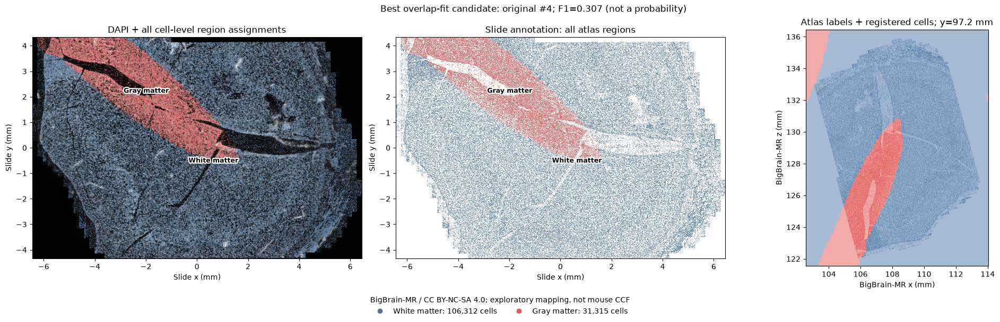

In [14]:
best_annotation, best_region_counts, best_annotation_figure = annotate_best_candidate(
    adata, match_results, density_candidate_table, candidate_points_and_labels,
    xy_mm, label_data_100, label_affine_100, region_names,
    dapi_enhanced, dapi_extent, OUTPUT_DIR,
)
display(best_region_counts)
display(best_annotation.head())
plt.show()


## TOP10 후보 전체의 세포별 atlas annotation

같은 방식(좌표 → 영역 ID → 영역명·색상 결합)을 적합도 순위 TOP10 후보 각각에 적용합니다. 한 행이 한 후보이며, 왼쪽은 슬라이드 좌표의 세포별 영역 배정, 오른쪽은 BigBrain-MR 라벨 절편과 등록된 세포입니다. 후보별 영역 세포 수는 `BigBrain_top10_region_counts.csv`로 저장됩니다. F1은 확률이 아니며, 모든 배정은 탐색적입니다.

,,region,Caudate,Cerebrospinal fluid,Gray matter,Putamen,Thalamus,White matter
fit_rank,original_rank,fit_score,,,,,,
1,4,0.307399,0,0,31315,0,0,106312
2,8,0.285714,0,0,23907,0,0,113720
3,5,0.278122,0,0,0,33468,0,104159
4,1,0.275449,0,0,33960,0,0,103667
5,9,0.249898,0,0,37543,0,0,100084
6,6,0.240128,0,0,25649,0,0,111978
7,7,0.231751,0,0,28671,0,0,108956
8,3,0.221950,0,0,35547,0,0,102080
9,10,0.178694,0,0,20417,0,0,117210


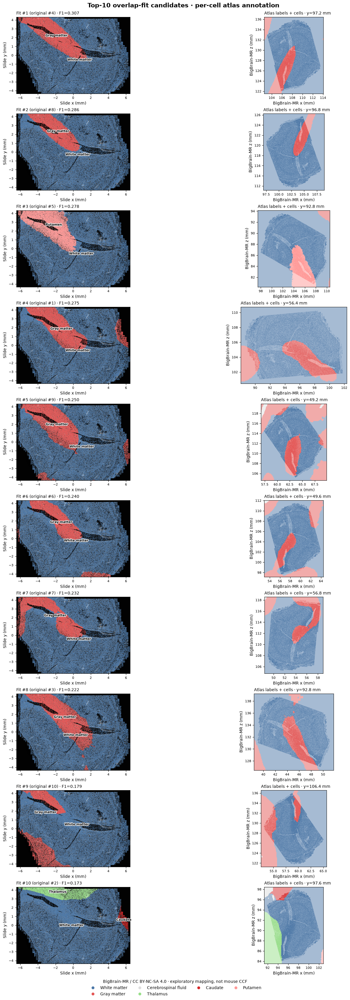

In [15]:
top10_region_counts, top10_annotation_figure = annotate_top_candidates(
    match_results, density_candidate_table, candidate_points_and_labels,
    xy_mm, label_data_100, label_affine_100, region_names,
    dapi_enhanced, dapi_extent, OUTPUT_DIR,
)
display(top10_region_counts.pivot_table(index=['fit_rank', 'original_rank', 'fit_score'],
                                        columns='region', values='n_cells',
                                        fill_value=0, aggfunc='sum'))
plt.show()


## 비교용 기준선: 마커 필터 없는 TOP10 voting 및 F1-weighted ensemble

마지막 TOP10 figure와 동일한 후보의 **세포별 영역 ID**를 원본 슬라이드 좌표에서 통합합니다. Voting은 동일 가중 다수결(plurality), ensemble은 `fit_score / sum(fit_score)` 가중 투표입니다. 동률(허용오차 1e-12)은 동률 영역을 지지하는 후보 중 적합도 순위가 가장 높은 후보의 표를 선택합니다. 배경(0)·CSF(3)도 투표에는 포함하되 최종 배정에서는 미배정·제외로 표시합니다.

두 방법의 최종 영역, 지지율, 방법 간 불일치, 영역별 비율을 비교합니다. 지지율과 F1은 **확률이나 해부학적 정확도가 아닙니다**. 서로 다른 후보의 atlas 좌표는 평균하지 않습니다. 독립적인 등록 검증이 필요한 탐색적 결과입니다.

앞선 변수들이 있으면 그대로 사용합니다. 새 `scrna` 커널에서는 저장된 후보 순위·좌표 CSV와 공개 100 µm atlas를 이용해 재투영하며, 이전 figure의 모든 후보별 영역 세포 수 및 1위 세포별 배정과 일치하는지 검사합니다. 전체 atlas를 메모리에 올리거나 긴 등록 탐색을 다시 실행하지 않습니다. 결과 그림과 세포별 CSV는 이 노트북 폴더에 저장합니다.

Atlas: [BigBrain-MR](https://zenodo.org/records/7432527), [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). 기존 라벨의 투표·가중 통합 및 슬라이드 오버레이이며 Allen mouse CCF가 아닙니다.

In [3]:
consensus_dir = OUTPUT_DIR

live_inputs = ('adata', 'xy_mm', 'match_results', 'density_candidate_table',
               'candidate_points_and_labels', 'region_names', 'dapi_enhanced', 'dapi_extent')
if all(name in globals() for name in live_inputs):
    consensus_ranked = (density_candidate_table.dropna(subset=['candidate_density_rank'])
                        .sort_values('candidate_density_rank').head(10).copy())
    consensus_xy, consensus_ids = xy_mm, adata.obs_names.copy()
    consensus_labels = np.stack([candidate_points_and_labels(match_results.loc[int(rank)])[1]
                                 for rank in consensus_ranked['original_rank']])
    consensus_names = region_names
    consensus_dapi, consensus_extent = dapi_enhanced, dapi_extent
    print('Using live Top-10 candidate projections.')
else:
    print('Restoring saved Top-10 candidates; streaming native atlas labels (no registration search).')
    consensus_ranked = (pd.read_csv(consensus_dir / 'BigBrain_fit_candidate_ranking.csv')
                        .dropna(subset=['candidate_density_rank'])
                        .sort_values('candidate_density_rank').head(10))
    saved_cells = pd.read_csv(consensus_dir / 'BigBrain_best_cell_annotation.csv', dtype={'cell_id': str})
    consensus_ids = pd.Index(saved_cells['cell_id'], name='cell_id')
    consensus_xy = saved_cells[['slide_x_mm', 'slide_y_mm']].to_numpy()
    saved_counts = pd.read_csv(consensus_dir / 'BigBrain_top10_region_counts.csv')
    consensus_names = dict(saved_counts[['region_id', 'region']].drop_duplicates().itertuples(index=False, name=None))
    consensus_labels = saved_top_candidate_labels(consensus_ranked, consensus_xy)
    if not np.array_equal(consensus_labels[0], saved_cells['bigbrain_region_id'].to_numpy()):
        raise ValueError('Restored best-candidate labels differ from the saved cell annotation.')
    for row, candidate in enumerate(consensus_ranked.itertuples(index=False)):
        expected = saved_counts.loc[saved_counts['original_rank'] == candidate.original_rank].set_index('region_id')['n_cells']
        actual = pd.Series(consensus_labels[row]).value_counts().sort_index()
        label_ids = expected.index.union(actual.index)
        if (expected.empty or not np.array_equal(actual.reindex(label_ids, fill_value=0),
                                                 expected.reindex(label_ids, fill_value=0))):
            raise ValueError(f'Candidate {candidate.original_rank}: counts differ from the last Top-10 figure.')
    data_dir = Path('/home/Data_Drive_8TB/kykim/CCF_annotation')
    saved_manifest = json.loads((data_dir / 'manifest.json').read_text())
    slide_width = saved_manifest['mosaic_width_pixels'] * saved_manifest['microns_per_pixel'] / 1000
    slide_height = saved_manifest['mosaic_height_pixels'] * saved_manifest['microns_per_pixel'] / 1000
    consensus_extent = (-slide_width / 2, slide_width / 2, -slide_height / 2, slide_height / 2)
    saved_dapi = tifffile.imread(data_dir / 'mosaic_DAPI_z0_downsampled.tif')
    small_dapi = cv2.resize(saved_dapi, (round(slide_width * 50), round(slide_height * 50)), interpolation=cv2.INTER_AREA)
    low, high = np.percentile(small_dapi, [1, 99.8])
    if high <= low:
        raise ValueError('Invalid DAPI intensity range.')
    scaled_dapi = np.uint8(np.clip((small_dapi.astype(float) - low) * 255 / (high - low), 0, 255))
    consensus_dapi = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(scaled_dapi)
    del saved_dapi
    print('Validated all 10 candidate counts and the best-candidate cell labels against saved outputs.')

display(consensus_ranked[['candidate_density_rank', 'original_rank', 'fit_score']]
        .assign(ensemble_weight=consensus_ranked['fit_score'] / consensus_ranked['fit_score'].sum()))

Restoring saved Top-10 candidates; streaming native atlas labels (no registration search).


<tifffile.TiffFile 'mosaic_DAPI_z0_downsampled.tif'> shaped series shape does not match page shape


Validated all 10 candidate counts and the best-candidate cell labels against saved outputs.


,candidate_density_rank,original_rank,fit_score,ensemble_weight
0,1,4,0.307399,0.125858
1,2,8,0.285714,0.116980
2,3,5,0.278122,0.113872
3,4,1,0.275449,0.112777
4,5,9,0.249898,0.102316
5,6,6,0.240128,0.098316
6,7,7,0.231751,0.094886
7,8,3,0.221950,0.090873
8,9,10,0.178694,0.073163
9,10,2,0.173313,0.070960


,method,region_id,region,n_cells,percent_cells
0,voting,1,White matter,111932,81.329972
1,voting,2,Gray matter,25695,18.670028
2,ensemble,1,White matter,111217,80.810451
3,ensemble,2,Gray matter,26410,19.189549


,slide_x_mm,slide_y_mm,voting_region_id,voting_region,voting_support,voting_margin,voting_tie,voting_status,ensemble_region_id,ensemble_region,ensemble_support,ensemble_margin,ensemble_tie,ensemble_status,voting_n_votes,methods_agree
cell_id,,,,,,,,,,,,,,,,
2451067200000100001,-6.048639,4.315529,1,White matter,0.6,0.4,False,exploratory atlas assignment,1,White matter,0.594425,0.373681,False,exploratory atlas assignment,6,True
2451067200000100002,-6.026273,4.310648,1,White matter,0.6,0.4,False,exploratory atlas assignment,1,White matter,0.594425,0.373681,False,exploratory atlas assignment,6,True
2451067200000100003,-5.921471,4.313423,1,White matter,0.6,0.4,False,exploratory atlas assignment,1,White matter,0.594425,0.373681,False,exploratory atlas assignment,6,True
2451067200000100004,-5.980150,4.314186,1,White matter,0.6,0.4,False,exploratory atlas assignment,1,White matter,0.594425,0.373681,False,exploratory atlas assignment,6,True
2451067200000100006,-6.212348,4.312623,1,White matter,0.7,0.6,False,exploratory atlas assignment,1,White matter,0.689311,0.563452,False,exploratory atlas assignment,7,True


Voting / ensemble agreement: 99.32%
Saved: /home/Data_Drive_8TB/kykim/.copilot/session-state/cfa80995-2338-42cb-964d-1d77a68ff21c/files/validation_outputs/BigBrain_top10_voting_ensemble.png


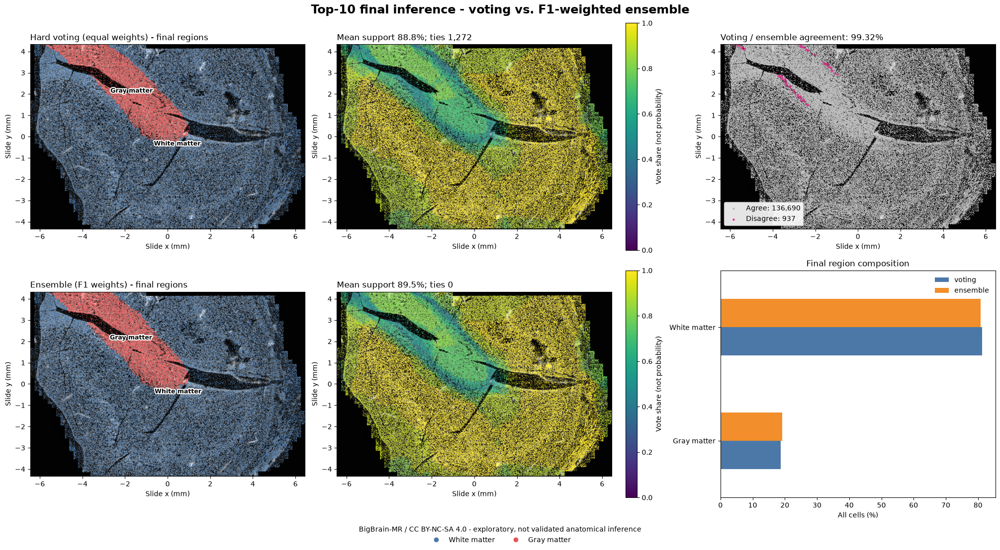

In [17]:
consensus_annotation, consensus_region_counts, consensus_figure = annotate_top_consensus(
    consensus_ids, consensus_xy, consensus_labels, consensus_ranked, consensus_names,
    consensus_dapi, consensus_extent, consensus_dir,
)
display(consensus_region_counts)
display(consensus_annotation.head())
print(f"Voting / ensemble agreement: {consensus_annotation['methods_agree'].mean():.2%}")
print('Saved:', consensus_dir / 'BigBrain_top10_voting_ensemble.png')
plt.show()

# 비교용 기준선: voting / ensemble gray-white DEG marker dot plots

기존 Top-10 voting과 fit-score-weighted ensemble의 **영역 라벨을 그대로** 사용하여 각각 white vs gray의 DEG를 구하고 두 개의 dot plot을 만듭니다. Voting 동률은 기존 파일의 fit-rank 순서에 따른 tie-break를 그대로 유지합니다. 영역 밖 label은 제외하며, 발현량 0인 세포는 포함합니다.

1,000개 측정 유전자의 세포별 count 합으로 10,000에 정규화한 뒤 log1p한 값에 대해 양측 Mann–Whitney U 검정(동률 보정)을 수행하고, 각 비교의 전체 1,000개 유전자에 대해 BH 보정합니다. 상수 유전자의 p값은 1로 처리합니다. log2FC는 정규화 count 평균의 비율에 pseudocount 1을 더하여 계산하며 white/gray 방향입니다. 두 방향 각각에서 **사전에 선택한 세포유형 마커 5개**가 조정 p < 0.05, |log2FC| > 1, 적어도 한 영역에서 양성률 ≥ 10%인지 확인합니다. 순서는 각 방향의 log2FC 기준입니다. 이는 상위 5개 전체 DEG가 아니라 생물학적 후보 중 선택한 예시입니다.

점 크기: 원본 count > 0인 세포 비율; 색: 모든 세포의 평균 log1p 정규화 발현량. 두 그림은 같은 색 범위를 사용합니다. Neuronal과 oligodendrocyte/myelin 마커는 각각 세포 유형을 나타내며 영역에 절대적으로 특이적이지 않습니다. 샘플/생물학적 반복이 없고 공간적으로 인접한 세포는 독립 반복이 아니므로 검정의 p값은 **탐색적 세포 수준 통계**입니다. 패널 구성, 세포 조성, 검출률, 공간 의존성의 영향을 받으므로 독립적인 조직 검증 없이 확증적 DEG 또는 정합 증거로 해석할 수 없습니다.

마커 배경: [피질 세포 마커 (SLC17A7, CAMK2A, MOBP)](https://www.nature.com/articles/s41598-026-51501-2), [CNS glia/myelin 표지자](https://pmc.ncbi.nlm.nih.gov/articles/PMC10043115/), [MYRF의 myelination 조절](https://pmc.ncbi.nlm.nih.gov/articles/PMC3742440/), [Human Protein Atlas: MYRF 및 oligodendrocyte 클러스터](https://www.proteinatlas.org/ENSG00000124920-MYRF/single+cell), [Human Protein Atlas: SYT1](https://www.proteinatlas.org/ENSG00000067715-SYT1/single+cell/brain).

In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

data_dir = DATA_DIR
out_dir = OUTPUT_DIR
deg_adata = sc.read_h5ad(data_dir / "adata.h5ad")
if not deg_adata.obs_names.is_unique or not deg_adata.var_names.is_unique:
    raise ValueError("Cell IDs and gene names must be unique.")
labels = pd.read_csv(out_dir / "BigBrain_top10_consensus_cell_annotation.csv",
                     dtype={"cell_id": str}).set_index("cell_id")
if not labels.index.is_unique:
    raise ValueError("Duplicate annotation cell IDs.")
missing = deg_adata.obs_names.difference(labels.index)
extra = labels.index.difference(deg_adata.obs_names)
if len(missing) or len(extra):
    raise ValueError(f"Annotation cell IDs: {len(missing)} missing, {len(extra)} extra.")
labels = labels.reindex(deg_adata.obs_names)

X = deg_adata.X.toarray() if hasattr(deg_adata.X, "toarray") else np.asarray(deg_adata.X)
if not np.isfinite(X).all() or (X < 0).any() or not np.equal(X, np.floor(X)).all():
    raise ValueError("Expected finite nonnegative integer transcript counts in deg_adata.X.")
counts = X.astype(np.float32, copy=False)
totals = counts.sum(axis=1, dtype=np.float64)
nonzero = totals > 0
norm = np.zeros_like(counts)
norm[nonzero] = counts[nonzero] * (10_000 / totals[nonzero, None])
lognorm = np.log1p(norm)
print(f"Cells: {deg_adata.n_obs:,}; panel genes: {deg_adata.n_vars:,}; zero-count cells retained: {(~nonzero).sum():,}")
print("Normalization: counts per 10,000 panel transcripts, followed by log1p.")
print("Two-sided cell-level Mann-Whitney U with tie correction; BH across all panel genes per comparison.")

results = {}
for method in ("voting", "ensemble"):
    label = labels[f"{method}_region"]
    if label.isna().any():
        raise ValueError(f"{method} has missing labels.")
    gray = label.eq("Gray matter").to_numpy()
    white = label.eq("White matter").to_numpy()
    if not gray.any() or not white.any():
        raise ValueError(f"{method} must contain both gray and white matter.")
    print(f"\n{method}: gray={gray.sum():,}, white={white.sum():,}, excluded={(~(gray | white)).sum():,}; ties included={labels[f'{method}_tie'].sum():,}")
    pvalues = np.ones(deg_adata.n_vars, dtype=float)
    informative = np.ptp(lognorm[gray | white], axis=0) > 0
    print(f"Constant genes assigned p=1: {(~informative).sum()}")
    for start in range(0, deg_adata.n_vars, 20):
        indices = np.flatnonzero(informative[start:start + 20]) + start
        if not len(indices):
            continue
        x = lognorm[np.ix_(white, indices)]
        y = lognorm[np.ix_(gray, indices)]
        pvalues[indices] = mannwhitneyu(x, y, axis=0, alternative="two-sided", method="asymptotic").pvalue
    if not np.isfinite(pvalues).all():
        raise ValueError(f"{method}: non-finite p-values for variable genes.")
    frac_white = (counts[white] > 0).mean(axis=0)
    frac_gray = (counts[gray] > 0).mean(axis=0)
    mean_white = norm[white].mean(axis=0, dtype=np.float64)
    mean_gray = norm[gray].mean(axis=0, dtype=np.float64)
    result = pd.DataFrame({
        "gene": deg_adata.var_names,
        "p_value": pvalues,
        "p_adj_bh": multipletests(pvalues, method="fdr_bh")[1],
        "log2fc_white_vs_gray": np.log2((mean_white + 1) / (mean_gray + 1)),
        "mean_normalized_white": mean_white,
        "mean_normalized_gray": mean_gray,
        "mean_log1p_white": lognorm[white].mean(axis=0, dtype=np.float64),
        "mean_log1p_gray": lognorm[gray].mean(axis=0, dtype=np.float64),
        "fraction_white": frac_white,
        "fraction_gray": frac_gray,
    })
    result.to_csv(out_dir / f"BigBrain_{method}_gray_white_DEG.csv", index=False)
    results[method] = result.set_index("gene")


Cells: 137,627; panel genes: 1,000; zero-count cells retained: 6,893
Normalization: counts per 10,000 panel transcripts, followed by log1p.
Two-sided cell-level Mann-Whitney U with tie correction; BH across all panel genes per comparison.

voting: gray=25,695, white=111,932, excluded=0; ties included=1,272
Constant genes assigned p=1: 40



ensemble: gray=26,410, white=111,217, excluded=0; ties included=0
Constant genes assigned p=1: 40


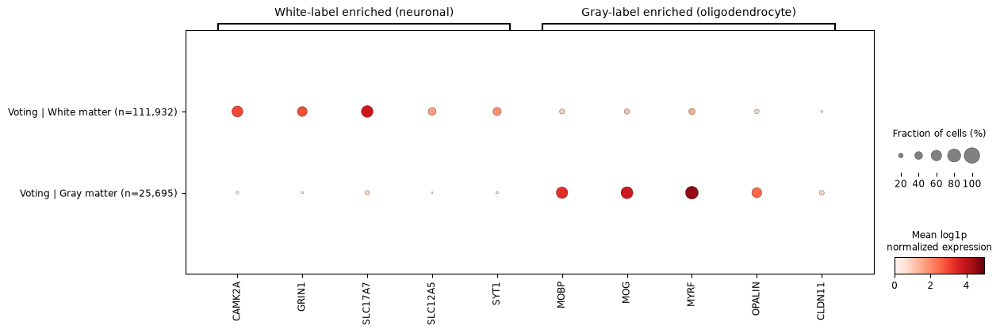

Saved /home/Data_Drive_8TB/kykim/.copilot/session-state/cfa80995-2338-42cb-964d-1d77a68ff21c/files/validation_outputs/BigBrain_voting_DEG_marker_dotplot.png


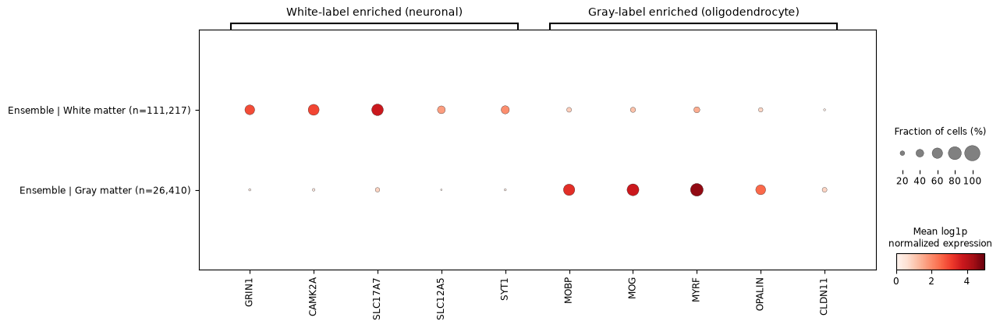

Saved /home/Data_Drive_8TB/kykim/.copilot/session-state/cfa80995-2338-42cb-964d-1d77a68ff21c/files/validation_outputs/BigBrain_ensemble_DEG_marker_dotplot.png


,method,marker_group,gene,log2fc_white_vs_gray,p_adj_bh,fraction_white,fraction_gray
0,voting,White-label enriched (neuronal),CAMK2A,3.6657,0.0,0.6346,0.0947
1,voting,White-label enriched (neuronal),GRIN1,3.6605,0.0,0.5455,0.0754
2,voting,White-label enriched (neuronal),SLC17A7,3.2084,0.0,0.6864,0.1942
3,voting,White-label enriched (neuronal),SLC12A5,3.0727,0.0,0.4039,0.0469
4,voting,White-label enriched (neuronal),SYT1,2.9516,0.0,0.4294,0.0713
5,voting,Gray-label enriched (oligodendrocyte),MOBP,-2.2279,0.0,0.2168,0.6685
6,voting,Gray-label enriched (oligodendrocyte),MOG,-1.9652,0.0,0.2400,0.7073
7,voting,Gray-label enriched (oligodendrocyte),MYRF,-1.9523,0.0,0.2900,0.7753
8,voting,Gray-label enriched (oligodendrocyte),OPALIN,-1.8360,0.0,0.1937,0.5551
9,voting,Gray-label enriched (oligodendrocyte),CLDN11,-1.6682,0.0,0.0687,0.2125


Adjusted p-values reported as 0 reflect numerical underflow, not an exact probability of zero.


In [19]:
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display

# These are cell-type markers, not exclusive anatomical region markers.
marker_candidates = {
    "White-label enriched (neuronal)": ["CAMK2A", "GRIN1", "SLC17A7", "SLC12A5", "SYT1"],
    "Gray-label enriched (oligodendrocyte)": ["MOBP", "MOG", "MYRF", "OPALIN", "CLDN11"],
}
selected_rows = []
for method, deg in results.items():
    selected = {}
    for group, candidates in marker_candidates.items():
        missing = [g for g in candidates if g not in deg.index]
        if missing:
            raise ValueError(f"{method}: markers missing from DEG results: {missing}")
        frame = deg.loc[candidates].copy()
        sign = 1 if group.startswith("White") else -1
        eligible = (
            (frame["p_adj_bh"] < 0.05)
            & (sign * frame["log2fc_white_vs_gray"] > 1)
            & (frame[["fraction_white", "fraction_gray"]].max(axis=1) >= 0.10)
        )
        if not eligible.all():
            raise ValueError(f"{method}: markers failing DEG criteria: {frame.index[~eligible].tolist()}")
        frame = frame.sort_values("log2fc_white_vs_gray", ascending=sign < 0)
        selected[group] = frame.index.tolist()
        frame.insert(0, "marker_group", group)
        frame.insert(0, "method", method)
        selected_rows.append(frame.reset_index())

    genes = [gene for group in selected.values() for gene in group]
    keep = labels[f"{method}_region"].isin(["White matter", "Gray matter"]).to_numpy()
    region = labels.loc[keep, f"{method}_region"]
    counts_by_region = region.value_counts()
    categories = [f"{method.capitalize()} | {name} (n={counts_by_region[name]:,})"
                  for name in ["White matter", "Gray matter"]]
    row_labels = region.map({
        name: category for name, category in zip(["White matter", "Gray matter"], categories)
    })
    obs = pd.DataFrame(
        {"region": pd.Categorical(row_labels.to_numpy(), categories=categories, ordered=True)},
        index=deg_adata.obs_names[keep],
    )
    var_indices = deg_adata.var_names.get_indexer(genes)
    plot_data = ad.AnnData(
        X=lognorm[np.ix_(keep, var_indices)],
        obs=obs,
        var=pd.DataFrame(index=pd.Index(genes, name="gene")),
    )
    dot = sc.pl.dotplot(
        plot_data, selected, groupby="region", use_raw=False,
        expression_cutoff=0, mean_only_expressed=False, standard_scale=None,
        cmap="Reds", vmin=0, vmax=5, dot_max=1, var_group_rotation=0,
        figsize=(13, 4), return_fig=True,
    )
    dot.legend(colorbar_title="Mean log1p\nnormalized expression",
               size_title="Fraction of cells (%)")
    image = out_dir / f"BigBrain_{method}_DEG_marker_dotplot.png"
    dot.savefig(image, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved {image}")

selected_df = pd.concat(selected_rows, ignore_index=True)
selected_df.to_csv(out_dir / "BigBrain_voting_ensemble_selected_DEG_markers.csv", index=False)
display(selected_df[["method", "marker_group", "gene", "log2fc_white_vs_gray",
                     "p_adj_bh", "fraction_white", "fraction_gray"]].round(4))
print("Adjusted p-values reported as 0 reflect numerical underflow, not an exact probability of zero.")


## 최종 단계: 지역별 마커 선별 → voting·F1 가중 ensemble

후보별로 백질(수초·희소돌기아교세포), 회백질(신경세포), putamen(선조체 marker; 회백질과 비교)을 평가합니다. 이 마커들은 해부학적 영역의 전용 마커가 아니며, putamen을 다른 선조체 영역과 구분한다는 뜻도 아닙니다. 현재 패널로 평가하지 않는 영역은 통과 처리하지 않습니다.

2 mm 체커보드에서 탐색용 및 확인용 마커를 서로 다른 공간 블록에 적용합니다. 같은 블록 내 두 영역에 각각 발현 총량이 0이 아닌 세포가 ≥20개 있어야 비교하며, 마커마다 ≥3개 블록, 검출률 차이 중앙값 ≥2%p, 양의 방향 블록 비율 ≥2/3을 요구합니다. 전체 세포의 ≥5%를 차지하는 모든 조직 라벨이 두 마커 세트를 통과해야 후보를 채택합니다. 이 기준은 동일 절편 내에서 발현 방향을 점검하는 필터이지 독립 표본의 해부학적 검증이나 유의성 검정은 아닙니다.

영상 정합 상위 100개를 모두 평가합니다. 마커 기준과 기존 밀도 기준을 둘 다 통과한 후보가 ≥2개일 때만 최종 라벨을 저장하며, 마커 근거가 없는 ROI 또는 과반 지지가 없는 세포는 미배정으로 남깁니다. 결과는 `BigBrain_marker_screen/` 아래 실행별 폴더에 저장합니다. 이 단계만 실행할 때는 데이터·좌표 및 함수 정의 셀을 실행한 뒤 저장된 TOP100 랭킹을 사용할 수 있습니다. 비교용 TOP10·DEG 셀은 최종 선별에 필요하지 않습니다.

In [10]:
import sys
from pathlib import Path

marker_module_dir = Path.cwd()
if not (marker_module_dir / 'bigbrain_marker_screen.py').is_file():
    marker_module_dir = marker_module_dir / 'CCF'
if not (marker_module_dir / 'bigbrain_marker_screen.py').is_file():
    raise FileNotFoundError('Start the kernel in the CCF folder or its workspace root.')
if str(marker_module_dir) not in sys.path:
    sys.path.insert(0, str(marker_module_dir))
from bigbrain_marker_screen import finalize_marker_consensus, marker_detection

if 'marker_density_candidate_table' in globals():
    marker_ranked = marker_density_candidate_table.copy()
    marker_labels = np.stack([candidate_points_and_labels(match_results.loc[int(rank)])[1]
                              for rank in marker_ranked['original_rank']])
else:
    marker_ranked = pd.read_csv(OUTPUT_DIR / 'BigBrain_fit_candidate_ranking_top100.csv')
    if len(marker_ranked) != 100:
        raise ValueError('Expected exactly 100 saved registration candidates.')
    marker_labels = saved_top_candidate_labels(marker_ranked, xy_mm)
if set(marker_ranked['original_rank']) != set(range(1, 101)) or len(marker_ranked) != 100:
    raise ValueError('Expected the complete set of 100 distinct original candidate ranks.')
marker_names = region_names if 'region_names' in globals() else {1: 'White matter', 2: 'Gray matter', 8: 'Putamen'}
marker_calls, marker_nonzero = marker_detection(adata, adata.obs_names)
marker_audit, marker_evidence, marker_annotation, marker_counts, marker_run = finalize_marker_consensus(
    marker_ranked, marker_labels, marker_calls, marker_nonzero, xy_mm,
    marker_names, _top_candidate_consensus, OUTPUT_DIR,
)
print(f"마커 통과: {marker_audit['passes_marker_screen'].sum()}/{len(marker_audit)}; "
      f"밀도·마커 동시 통과: {marker_audit['eligible_for_consensus'].sum()}/{len(marker_audit)}")
display(marker_audit[['original_rank', 'fit_score', 'major_region_ids',
                      'marker_supported_region_ids', 'passes_marker_screen', 'eligible_for_consensus']])
if marker_counts is None:
    print('밀도·마커 동시 통과 후보가 2개 미만이므로 최종 라벨을 생성하지 않았습니다.')
else:
    display(marker_counts)
print('Marker screening results:', marker_run)


마커 통과: 0/100; 밀도·마커 동시 통과: 0/100


,original_rank,fit_score,major_region_ids,marker_supported_region_ids,passes_marker_screen,eligible_for_consensus
0,49,0.307953,"1,2",,False,False
1,4,0.307399,"1,2",,False,False
2,94,0.304607,"1,15,17",,False,False
3,44,0.301761,"1,2,8",,False,False
4,80,0.301661,"1,2",,False,False
...,...,...,...,...,...,...
95,12,0.065926,"1,9,10,11",,False,False
96,21,NaN,"1,2",,False,False
97,76,NaN,"1,10,11,15",,False,False
98,85,NaN,"1,2",,False,False


밀도·마커 동시 통과 후보가 2개 미만이므로 최종 라벨을 생성하지 않았습니다.
Marker screening results: /home/Data_Drive_8TB/kykim/0. Jupyter/CCF/BigBrain_marker_screen/20261120T003919.939246Z


## TOP100 마커 컷오프 민감도 (scree plot)

세포나 환자 수가 아닌 정합 후보 수를 집계합니다. 왼쪽은 기존처럼 영역당 마커 4개를 요구하면서 검출률 차이 컷오프를 낮춥니다. 오른쪽은 블록 방향 일치율을 50%로 두고 영역당 최소 마커 수를 4개에서 1개까지 낮춥니다. 오른쪽의 부분 통과는 주요 영역 중 최소 한 곳만 통과한 경우도 포함합니다. 차이 컷오프 0에서도 양의 차이만 인정합니다. 블록 수·세포 수·밀도 기준은 유지하며, 이 민감도 분석은 기존 최종 라벨을 변경하지 않습니다.

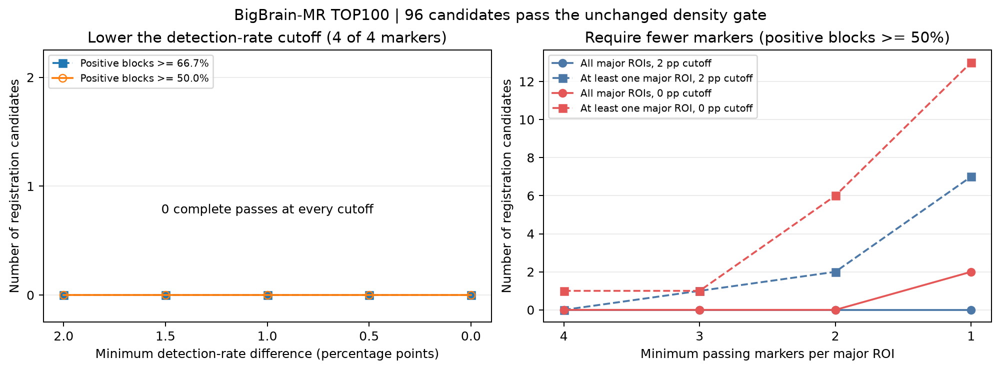

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import Image, display

if 'marker_run' in globals():
    scree_dir = marker_run
else:
    scree_root = Path.cwd() / 'BigBrain_marker_screen'
    if not scree_root.is_dir():
        scree_root = Path.cwd() / 'CCF' / 'BigBrain_marker_screen'
    scree_dir = max(p.parent for p in scree_root.glob('*/summary.json')
                    if json.loads(p.read_text())['n_candidates'] == 100)
scree_summary = json.loads((scree_dir / 'summary.json').read_text())
scree_audit = pd.read_csv(scree_dir / 'candidate_audit.csv')
scree_evidence = pd.read_csv(scree_dir / 'marker_evidence.csv')
if scree_summary['n_candidates'] != 100 or scree_audit['original_rank'].nunique() != 100:
    raise ValueError('The cutoff plot requires the complete TOP100 audit.')
scree_eligible = scree_audit.loc[scree_audit['passes_density_screen']]
major_rois = {r.original_rank: {int(x) for x in str(r.major_region_ids).split(',') if x.isdigit()}
              for r in scree_eligible.itertuples(index=False)}

def count_at_cutoff(min_delta_pp, min_block_share, min_markers):
    delta = scree_evidence['median_detection_delta']
    hits = scree_evidence.loc[delta.gt(0) & delta.ge(min_delta_pp / 100)
                              & scree_evidence['positive_block_share'].ge(min_block_share)]
    counts = hits.groupby(['original_rank', 'target_id'])['gene'].nunique()
    passed_rois = {rank: set() for rank in major_rois}
    for rank, roi in counts[counts.ge(min_markers)].index:
        if rank in passed_rois:
            passed_rois[rank].add(roi)
    all_ranks = [rank for rank, rois in major_rois.items() if rois and rois <= passed_rois[rank]]
    any_ranks = [rank for rank, rois in major_rois.items() if rois & passed_rois[rank]]
    return {'min_detection_delta_pp': min_delta_pp, 'min_positive_block_share': min_block_share,
            'min_markers_per_roi': min_markers, 'n_all_major_rois': len(all_ranks),
            'n_at_least_one_major_roi': len(any_ranks),
            'all_major_roi_original_ranks': ','.join(map(str, sorted(all_ranks)))}

scree = pd.DataFrame([count_at_cutoff(d, b, k) for d in (2, 1.5, 1, 0.5, 0)
                      for b in (scree_summary['min_positive_block_share'], 0.5) for k in (4, 3, 2, 1)])
baseline = scree.loc[(scree.min_detection_delta_pp == 100 * scree_summary['min_detection_delta'])
                     & (scree.min_positive_block_share == scree_summary['min_positive_block_share'])
                     & (scree.min_markers_per_roi == 4), 'n_all_major_rois'].item()
if baseline != scree_summary['n_passed']:
    raise RuntimeError('Cutoff sweep failed to reproduce the original candidate count.')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for share, linestyle, marker in ((2 / 3, '--', 's'), (0.5, '-', 'o')):
    subset = scree.loc[scree.min_markers_per_roi.eq(4) & scree.min_positive_block_share.eq(share)]
    axes[0].plot(subset.min_detection_delta_pp, subset.n_all_major_rois, marker=marker,
                 linestyle=linestyle, fillstyle='none' if share == 0.5 else 'full',
                 label=f'Positive blocks >= {share:.1%}')
axes[0].set(title='Lower the detection-rate cutoff (4 of 4 markers)',
            xlabel='Minimum detection-rate difference (percentage points)', xlim=(2.1, -0.1),
            xticks=[2, 1.5, 1, 0.5, 0])
if scree.loc[scree.min_markers_per_roi.eq(4), 'n_all_major_rois'].max() == 0:
    axes[0].set_ylim(-0.25, 2.25)
    axes[0].text(0.5, 0.4, '0 complete passes at every cutoff',
                 transform=axes[0].transAxes, ha='center')
for cutoff, color in ((2, '#4c78a8'), (0, '#e45756')):
    subset = scree.loc[scree.min_positive_block_share.eq(0.5) & scree.min_detection_delta_pp.eq(cutoff)]
    axes[1].plot(subset.min_markers_per_roi, subset.n_all_major_rois, 'o-', color=color,
                 label=f'All major ROIs, {cutoff} pp cutoff')
    axes[1].plot(subset.min_markers_per_roi, subset.n_at_least_one_major_roi, 's--', color=color,
                 label=f'At least one major ROI, {cutoff} pp cutoff')
axes[1].set(title='Require fewer markers (positive blocks >= 50%)',
            xlabel='Minimum passing markers per major ROI', xlim=(4.15, 0.85), xticks=[4, 3, 2, 1])
for ax in axes:
    ax.set_ylabel('Number of registration candidates')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle(f'BigBrain-MR TOP100 | {len(scree_eligible)} candidates pass the unchanged density gate')
scree.to_csv(scree_dir / 'marker_cutoff_scree.csv', index=False)
scree_png = scree_dir / 'marker_cutoff_scree.png'
fig.savefig(scree_png, dpi=180, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(scree_png)))

In [2]:
# Scree 오른쪽: 주요 ROI 하나 이상, 마커 3개 이상, 0%p, 방향 일치 블록 50% 이상.
selection = count_at_cutoff(0, 0.5, 3)
selected_hits = scree_evidence.loc[
    scree_evidence['median_detection_delta'].gt(0)
    & scree_evidence['positive_block_share'].ge(0.5)
    & scree_evidence['original_rank'].isin(major_rois)
].copy()
selected_hits = selected_hits.loc[
    [r.target_id in major_rois[r.original_rank] for r in selected_hits.itertuples(index=False)]
]
marker_counts_per_roi = selected_hits.groupby(['original_rank', 'target_id'])['gene'].transform('nunique')
selected_hits = selected_hits.loc[marker_counts_per_roi.ge(3)].copy()
selected_hits = selected_hits.drop(columns='status').rename(columns={'target_id': 'roi_id'})
selected_hits['roi'] = selected_hits['roi_id'].map({1: 'White matter', 2: 'Gray matter', 8: 'Putamen'})
selected_ranks = sorted(selected_hits['original_rank'].unique())
if len(selected_ranks) != selection['n_at_least_one_major_roi']:
    raise RuntimeError('Selected candidate count does not match the scree plot.')
selected_hits.to_csv(scree_dir / 'marker_selection_any_roi_min3_0pp.csv', index=False)
print(f'선별 후보: {len(selected_ranks)}/{len(major_rois)}; 원래 정합 순위: {selected_ranks}')
display(selected_hits[['original_rank', 'roi', 'gene', 'median_detection_delta', 'positive_block_share']])
if len(selected_ranks) < 2:
    print('후보가 2개 미만이므로 voting·ensemble은 실행하지 않습니다.')

선별 후보: 1/96; 원래 정합 순위: [np.int64(44)]


,original_rank,roi,gene,median_detection_delta,positive_block_share
20,44,White matter,MOG,0.057270,1.000000
21,44,White matter,CLDN11,0.019630,0.666667
22,44,White matter,MOBP,0.031734,0.800000
23,44,White matter,OPALIN,0.030852,0.800000


후보가 2개 미만이므로 voting·ensemble은 실행하지 않습니다.


## 선별된 단일 후보: 정합 이미지와 마커 dot plot

DAPI 좌표의 세포 라벨과 atlas 절편을 따로 보여줍니다. Dot plot은 백질·회백질·Putamen을 각각 나머지 두 영역의 세포 전체와 비교한 one-vs-rest DEG에서 영역당 상위 2개를 선택합니다. 전체 패널을 CP10K 후 log1p 변환하고 총 발현량 0인 세포는 제외합니다. 양측 Mann–Whitney U(동률 보정), 비교별 전체 유전자 BH 보정 후 q<0.05, log2((평균 CP10K+1)/(나머지 평균 CP10K+1))≥0.25, 해당 영역 검출률≥10%, 나머지보다 높은 검출률을 요구하고 log2FC 내림차순으로 선택합니다. pooled rest 비교이므로 다른 두 영역 각각에 특이적임을 보장하지 않습니다. 동일 절편 세포 수준의 탐색적 DEG이며 공간적 상관·표본 간 변이는 검정하지 않습니다. 기존 정합 선별 마커와는 별개로 현재 배정 라벨을 설명하는 그림이며 최종 annotation이 아닙니다.

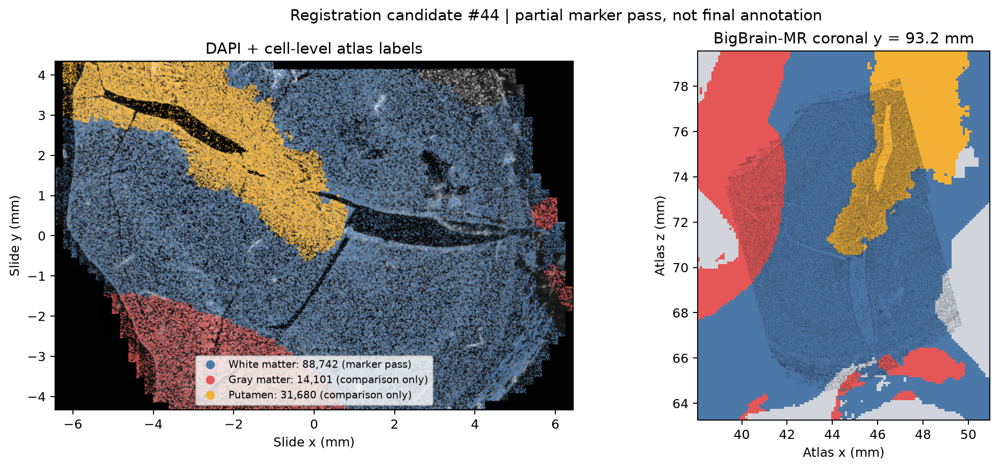

In [6]:
import gzip
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D

if len(selected_ranks) != 1:
    raise ValueError('This visualization expects exactly one selected candidate.')
plot_rank = int(selected_ranks[0])
plot_candidate = scree_audit.set_index('original_rank').loc[plot_rank]
if 'label_data_100' in globals() and 'label_affine_100' in globals():
    plot_atlas, plot_affine = label_data_100, label_affine_100
else:
    url = 'https://zenodo.org/records/7432527/files/BigBrainMR_Labels_100um.nii.gz'
    with requests.get(url, timeout=(30, 600)) as response:
        response.raise_for_status()
        image = nib.Nifti1Image.from_bytes(gzip.decompress(response.content))
    plot_atlas, plot_affine = np.asanyarray(image.dataobj), image.affine
    del image
if not np.allclose(plot_affine, np.diag([0.1, 0.1, 0.1, 1])):
    raise ValueError('Unexpected BigBrain-MR label grid.')
xz = (Affine2D().rotate_deg(plot_candidate.angle_deg)
      .translate(plot_candidate.x_mm, plot_candidate.z_mm).transform(xy_mm))
points = np.column_stack((xz[:, 0], np.full(len(xz), plot_candidate.y_mm), xz[:, 1]))
ijk = np.floor(nib.affines.apply_affine(np.linalg.inv(plot_affine), points) + 0.5).astype(int)
inside = ((ijk >= 0) & (ijk < np.asarray(plot_atlas.shape))).all(axis=1)
plot_labels = np.zeros(len(xz), dtype=np.uint8)
plot_labels[inside] = plot_atlas[tuple(ijk[inside].T)]
outside_pct = 100 * np.isin(plot_labels, [0, 3]).mean()
if not np.isclose(outside_pct, plot_candidate.outside_cells_pct, atol=1e-8):
    raise ValueError('Projected labels do not match the saved candidate coverage.')
if set(major_rois[plot_rank]) != set(np.flatnonzero(np.bincount(plot_labels) / len(plot_labels) >= 0.05)) - {0, 3}:
    raise ValueError('Projected major ROIs do not match the saved candidate audit.')

plot_rois = sorted(major_rois[plot_rank])
roi_names = {1: 'White matter', 2: 'Gray matter', 8: 'Putamen'}
passed_rois = set(selected_hits['roi_id'])
roi_colors = {1: '#4c78a8', 2: '#e45756', 8: '#f2b134'}
lo = np.maximum(ijk[:, [0, 2]].min(axis=0) - 12, 0)
hi = np.minimum(ijk[:, [0, 2]].max(axis=0) + 13, np.asarray(plot_atlas.shape)[[0, 2]])
atlas_crop = plot_atlas[lo[0]:hi[0], ijk[0, 1], lo[1]:hi[1]].T.copy()
del plot_atlas
atlas_classes = np.zeros(atlas_crop.shape, dtype=np.uint8)
for color_index, roi_id in enumerate(plot_rois, 1):
    atlas_classes[atlas_crop == roi_id] = color_index
bounds = 0.1 * np.array([lo[0] - 0.5, hi[0] - 0.5, lo[1] - 0.5, hi[1] - 0.5])
fig, (slide_ax, atlas_ax) = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
slide_ax.imshow(dapi_enhanced, cmap='gray', origin='upper', extent=dapi_extent)
colors = ListedColormap(['#d1d5db', *[roi_colors[x] for x in plot_rois]])
atlas_ax.imshow(atlas_classes, cmap=colors, norm=BoundaryNorm(np.arange(colors.N + 1) - 0.5, colors.N),
                origin='lower', extent=bounds, interpolation='nearest')
roi_handles = []
for roi_id in plot_rois:
    mask = plot_labels == roi_id
    slide_ax.scatter(*xy_mm[mask].T, s=1, c=roi_colors[roi_id], alpha=0.55, linewidths=0)
    status = 'marker pass' if roi_id in passed_rois else 'comparison only'
    roi_handles.append(Line2D([], [], marker='o', linestyle='', color=roi_colors[roi_id],
                              label=f'{roi_names[roi_id]}: {mask.sum():,} ({status})'))
atlas_ax.scatter(*xz[inside].T, s=0.45, c='#1f2937', alpha=0.14, linewidths=0)
slide_ax.set(title='DAPI + cell-level atlas labels', xlabel='Slide x (mm)', ylabel='Slide y (mm)', aspect='equal')
atlas_ax.set(title=f'BigBrain-MR coronal y = {plot_candidate.y_mm:.1f} mm',
             xlabel='Atlas x (mm)', ylabel='Atlas z (mm)', aspect='equal')
slide_ax.legend(handles=roi_handles, loc='lower center', fontsize=8)
fig.suptitle(f'Registration candidate #{plot_rank} | partial marker pass, not final annotation')
registration_png = scree_dir / f'candidate_{plot_rank}_registration.png'
fig.savefig(registration_png, dpi=180, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(registration_png)))

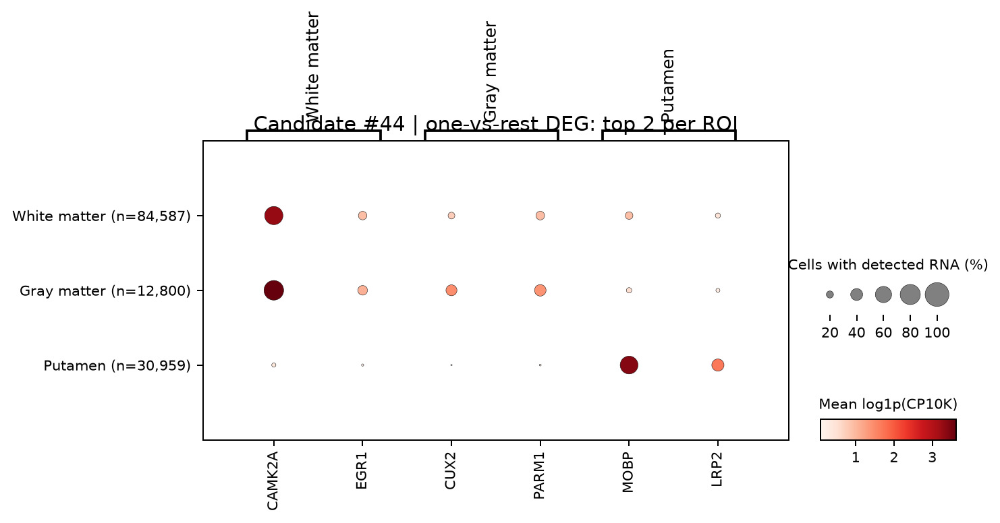

,roi,gene,log2fc_target_vs_rest,p_adj_bh,fraction_target,fraction_rest
0,White matter,CAMK2A,1.490293,0.0,0.701266,0.295459
1,White matter,EGR1,1.475650,0.0,0.253349,0.117530
2,Gray matter,CUX2,1.275591,0.0,0.355859,0.142748
3,Gray matter,PARM1,0.973664,0.0,0.380078,0.199842
4,Putamen,MOBP,2.498718,0.0,0.678769,0.208642
5,Putamen,LRP2,2.251015,0.0,0.409800,0.125119


In [7]:
import anndata as ad
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

if len(plot_labels) != adata.n_obs or set(plot_rois) != {1, 2, 8}:
    raise ValueError('Expected cell-aligned White matter, Gray matter and Putamen labels.')
if not adata.var_names.is_unique:
    raise ValueError('DEG gene names must be unique.')
totals = np.asarray(adata.X.sum(axis=1), dtype=np.float64).ravel()
keep = (totals > 0) & np.isin(plot_labels, plot_rois)
deg_counts = adata[keep].X
deg_counts = deg_counts.toarray() if hasattr(deg_counts, 'toarray') else np.asarray(deg_counts)
if not np.isfinite(deg_counts).all() or (deg_counts < 0).any() or not np.equal(deg_counts, np.floor(deg_counts)).all():
    raise ValueError('Expected finite nonnegative integer transcript counts.')
deg_norm = deg_counts.astype(np.float32) * (10000 / totals[keep, None])
deg_log = np.log1p(deg_norm)
deg_labels = plot_labels[keep]
deg_rows = []
for roi_id in plot_rois:
    target = deg_labels == roi_id
    rest = ~target
    if min(target.sum(), rest.sum()) < 20:
        raise ValueError(f'{roi_names[roi_id]}: insufficient cells for one-vs-rest DEG.')
    pvalues = np.ones(adata.n_vars)
    for start in range(0, adata.n_vars, 20):
        stop = min(start + 20, adata.n_vars)
        pvalues[start:stop] = mannwhitneyu(deg_log[target, start:stop], deg_log[rest, start:stop],
                                          axis=0, alternative='two-sided', method='asymptotic').pvalue
    if not np.isfinite(pvalues).all():
        raise ValueError(f'{roi_names[roi_id]}: nonfinite DEG p-values.')
    mean_target = deg_norm[target].mean(axis=0)
    mean_rest = deg_norm[rest].mean(axis=0)
    deg_rows.append(pd.DataFrame({
        'roi_id': roi_id, 'roi': roi_names[roi_id], 'gene': adata.var_names,
        'n_target': target.sum(), 'n_rest': rest.sum(), 'p_value': pvalues,
        'p_adj_bh': multipletests(pvalues, method='fdr_bh')[1],
        'log2fc_target_vs_rest': np.log2((mean_target + 1) / (mean_rest + 1)),
        'mean_cp10k_target': mean_target, 'mean_cp10k_rest': mean_rest,
        'fraction_target': (deg_counts[target] > 0).mean(axis=0),
        'fraction_rest': (deg_counts[rest] > 0).mean(axis=0),
    }))
candidate_deg = pd.concat(deg_rows, ignore_index=True)
candidate_deg.to_csv(scree_dir / f'candidate_{plot_rank}_one_vs_rest_DEG.csv', index=False)
selected_deg_rows, deg_marker_groups = [], {}
for roi_id in plot_rois:
    eligible = candidate_deg.loc[candidate_deg.roi_id.eq(roi_id) & candidate_deg.p_adj_bh.lt(0.05)
                                 & candidate_deg.log2fc_target_vs_rest.ge(0.25)
                                 & candidate_deg.fraction_target.ge(0.10)
                                 & candidate_deg.fraction_target.gt(candidate_deg.fraction_rest)]
    top = eligible.sort_values(['log2fc_target_vs_rest', 'p_adj_bh', 'gene'],
                               ascending=[False, True, True]).head(2)
    if len(top) != 2:
        raise ValueError(f'{roi_names[roi_id]} has fewer than two eligible positive DEGs; see the full DEG CSV.')
    selected_deg_rows.append(top)
    deg_marker_groups[roi_names[roi_id]] = top['gene'].tolist()
selected_deg = pd.concat(selected_deg_rows, ignore_index=True)
if not selected_deg['gene'].is_unique:
    raise ValueError('Top one-vs-rest genes overlap across ROIs; inspect the full DEG results before plotting.')
selected_deg.to_csv(scree_dir / f'candidate_{plot_rank}_one_vs_rest_top2_markers.csv', index=False)
plot_genes = selected_deg['gene'].tolist()
plot_expr = deg_log[:, adata.var_names.get_indexer(plot_genes)]
roi_categories = {roi_id: f'{roi_names[roi_id]} (n={(keep & (plot_labels == roi_id)).sum():,})'
                  for roi_id in plot_rois}
plot_obs = pd.DataFrame({'ROI': pd.Categorical([roi_categories[x] for x in plot_labels[keep]],
                                              categories=list(roi_categories.values()), ordered=True)},
                        index=adata.obs_names[keep])
plot_adata = ad.AnnData(X=plot_expr, obs=plot_obs, var=pd.DataFrame(index=plot_genes))
dot = sc.pl.dotplot(plot_adata, deg_marker_groups, groupby='ROI', use_raw=False, mean_only_expressed=False,
                    expression_cutoff=0, dot_max=1, cmap='Reds', figsize=(8, 3.2),
                    title=f'Candidate #{plot_rank} | one-vs-rest DEG: top 2 per ROI', return_fig=True)
dot.legend(colorbar_title='Mean log1p(CP10K)', size_title='Cells with detected RNA (%)')
markers_png = scree_dir / f'candidate_{plot_rank}_marker_dotplot.png'
dot.savefig(markers_png, dpi=180, bbox_inches='tight', facecolor='white')
dot.savefig(scree_dir / f'candidate_{plot_rank}_one_vs_rest_top2_dotplot.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.close('all')
display(Image(filename=str(markers_png)))
display(selected_deg[['roi', 'gene', 'log2fc_target_vs_rest', 'p_adj_bh', 'fraction_target', 'fraction_rest']])

## 44번 후보 위치의 실제 reference 이미지

BigBrain-MR의 400 µm 조직 영상(Histo)과 합성 T1 영상을 표시합니다. 위 행은 전체 관상 절편, 아래 행은 후보 영역 확대입니다. 청록색 사각형은 원본 DAPI 전체 영상의 물리적 범위를 후보 변환으로 옮긴 것으로, 실제 조직 경계는 아닙니다. T1은 환자의 원본 MRI가 아니라 BigBrain-MR 합성 영상입니다.

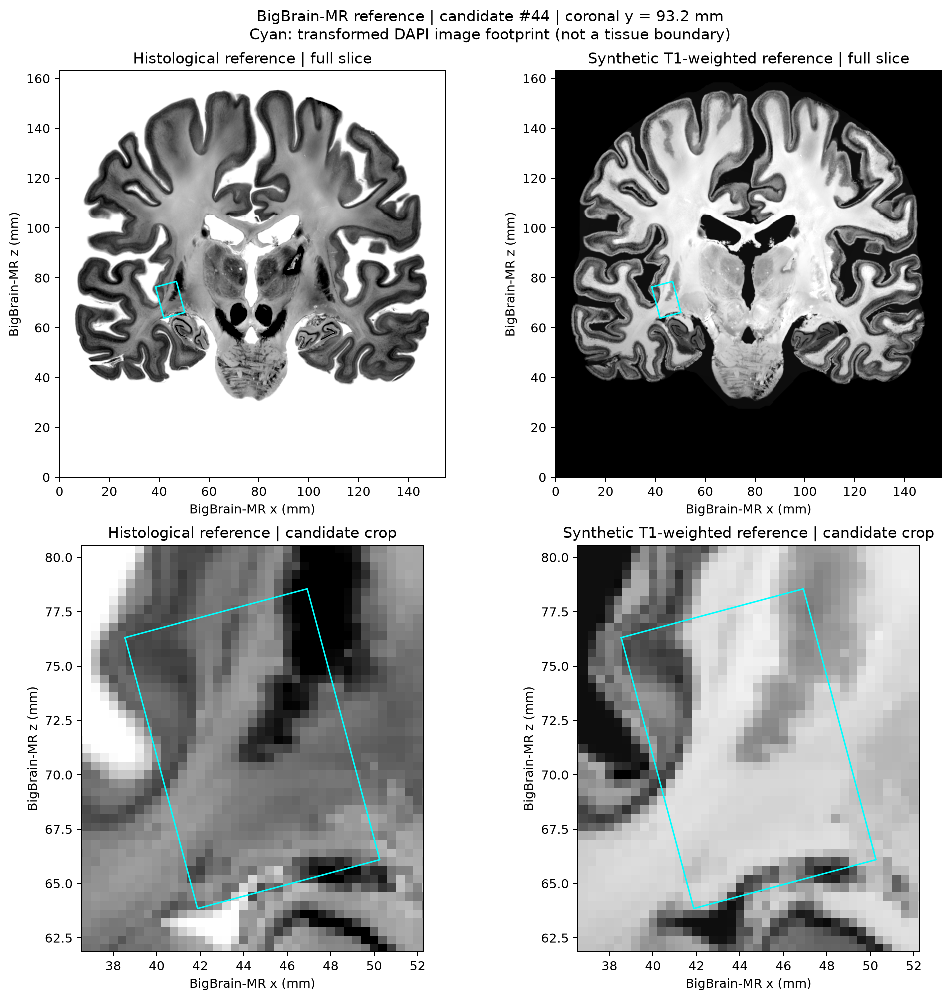

In [1]:
from pathlib import Path
import gzip
import json
import requests
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.transforms import Affine2D
from IPython.display import Image, display

reference_root = Path.cwd()
if not (reference_root / 'BigBrain_marker_screen').is_dir():
    reference_root = reference_root / 'CCF'
reference_runs = [p.parent for p in (reference_root / 'BigBrain_marker_screen').glob('*/marker_selection_any_roi_min3_0pp.csv')]
reference_run = max(reference_runs)
reference_selection = pd.read_csv(reference_run / 'marker_selection_any_roi_min3_0pp.csv')
if reference_selection['original_rank'].nunique() != 1:
    raise ValueError('Expected exactly one selected reference candidate.')
reference_rank = int(reference_selection['original_rank'].iloc[0])
reference_candidate = pd.read_csv(reference_run / 'candidate_audit.csv').set_index('original_rank').loc[reference_rank]
reference_manifest = json.loads(Path('/home/Data_Drive_8TB/kykim/CCF_annotation/manifest.json').read_text())
ref_width = reference_manifest['mosaic_width_pixels'] * reference_manifest['microns_per_pixel'] / 1000
ref_height = reference_manifest['mosaic_height_pixels'] * reference_manifest['microns_per_pixel'] / 1000
corners = np.array([[-ref_width/2, -ref_height/2], [ref_width/2, -ref_height/2],
                    [ref_width/2, ref_height/2], [-ref_width/2, ref_height/2], [-ref_width/2, -ref_height/2]])
reference_outline = (Affine2D().rotate_deg(reference_candidate.angle_deg)
                     .translate(reference_candidate.x_mm, reference_candidate.z_mm).transform(corners))
zoom_low, zoom_high = reference_outline.min(axis=0) - 2, reference_outline.max(axis=0) + 2
ref_fig, ref_axes = plt.subplots(2, 2, figsize=(11, 11), layout='constrained')
reference_grid = None
for column, (contrast, title) in enumerate((('Histo', 'Histological reference'),
                                           ('T1weighted', 'Synthetic T1-weighted reference'))):
    reference_url = f'https://zenodo.org/records/7432527/files/BigBrainMR_{contrast}_400um.nii.gz'
    with requests.get(reference_url, timeout=(30, 600)) as response:
        response.raise_for_status()
        ref_image = nib.Nifti1Image.from_bytes(gzip.decompress(response.content))
    if not np.allclose(ref_image.affine[:3, :3], np.eye(3) * 0.4):
        raise ValueError('Unexpected reference orientation or voxel size.')
    if reference_grid is not None and (ref_image.shape != reference_grid[0]
                                       or not np.allclose(ref_image.affine, reference_grid[1])):
        raise ValueError('Reference contrasts do not share the same grid.')
    reference_grid = (ref_image.shape, ref_image.affine.copy())
    ref_section = int(np.floor((reference_candidate.y_mm - ref_image.affine[1, 3]) / ref_image.affine[1, 1] + 0.5))
    if not 0 <= ref_section < ref_image.shape[1]:
        raise ValueError('Candidate section is outside the reference image.')
    if ref_section != int(reference_candidate.section_index):
        raise ValueError('Reference slice does not match the saved registration candidate.')
    ref_slice = np.asanyarray(ref_image.dataobj)[:, ref_section, :].T.copy()
    ref_extent = (ref_image.affine[0, 3] - 0.2, ref_image.affine[0, 3] + (ref_image.shape[0] - 0.5) * 0.4,
                  ref_image.affine[2, 3] - 0.2, ref_image.affine[2, 3] + (ref_image.shape[2] - 0.5) * 0.4)
    valid_signal = ref_slice[ref_slice > 0]
    if not len(valid_signal):
        raise ValueError('Reference slice contains no positive signal.')
    ref_vmin, ref_vmax = np.percentile(valid_signal, [1, 99])
    for row in (0, 1):
        ax = ref_axes[row, column]
        ax.imshow(ref_slice, cmap='gray', origin='lower', extent=ref_extent,
                  vmin=ref_vmin, vmax=ref_vmax, interpolation='nearest')
        ax.plot(*reference_outline.T, color='cyan', linewidth=1.2)
        ax.set(title=title + (' | full slice' if row == 0 else ' | candidate crop'),
               xlabel='BigBrain-MR x (mm)', ylabel='BigBrain-MR z (mm)', aspect='equal')
        if row == 1:
            ax.set_xlim(zoom_low[0], zoom_high[0])
            ax.set_ylim(zoom_low[1], zoom_high[1])
    del ref_image
ref_fig.suptitle(f'BigBrain-MR reference | candidate #{reference_rank} | coronal y = {reference_candidate.y_mm:.1f} mm\n'
                  'Cyan: transformed DAPI image footprint (not a tissue boundary)')
reference_png = reference_run / f'candidate_{reference_rank}_reference_images.png'
ref_fig.savefig(reference_png, dpi=180, bbox_inches='tight', facecolor='white')
plt.close(ref_fig)
display(Image(filename=str(reference_png)))

## 백질·회백질·Putamen별 관련 후보 선별

후보의 대표 밀도 영역(`region`)과 무관하게 각 주요 ROI를 별도로 평가합니다. 동일한 마커 ≥3개, 검출률 차이 >0, 방향 일치 블록 ≥50% 조건과 기존 밀도 기준을 유지합니다. 영역별 표에는 비교 가능한 마커 수와 방향 조건을 통과한 마커 수를 기록합니다. 공간 블록이 부족한 경우는 판정 불가이며, 탈락 후보를 대체 통과시키지 않습니다. 통과 영역만 마커 근거가 있는 것으로 해석하고 다른 영역의 라벨은 검증된 것으로 취급하지 않습니다.

status,density_screen_failed,insufficient_matched_blocks,marker_direction_not_supported,not_a_major_roi,pass
roi,,,,,
White matter,4,18,65,12,1
Gray matter,3,3,66,28,0
Putamen,0,7,0,93,0



White matter: 1 passing candidates / 84 major-ROI, density-supported candidates


,original_rank,n_measurable_markers,n_passing_markers,passing_genes,status
9,44,4,4,"MOG,CLDN11,MOBP,OPALIN",pass
165,14,4,2,"MOBP,OPALIN",marker_direction_not_supported
240,68,4,2,"MOBP,OPALIN",marker_direction_not_supported
264,97,4,2,"MOBP,OPALIN",marker_direction_not_supported
267,10,4,2,"MOG,CLDN11",marker_direction_not_supported


White matter — registration candidate #44; supported markers: MOG,CLDN11,MOBP,OPALIN


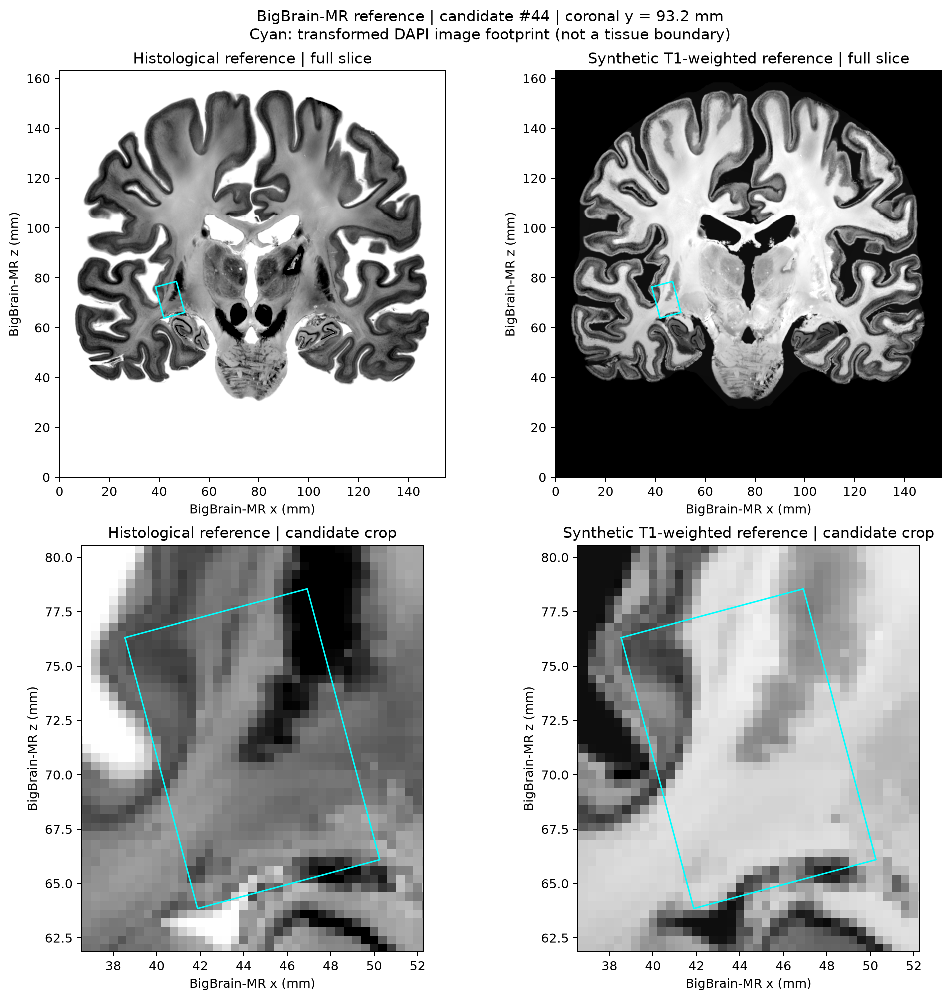

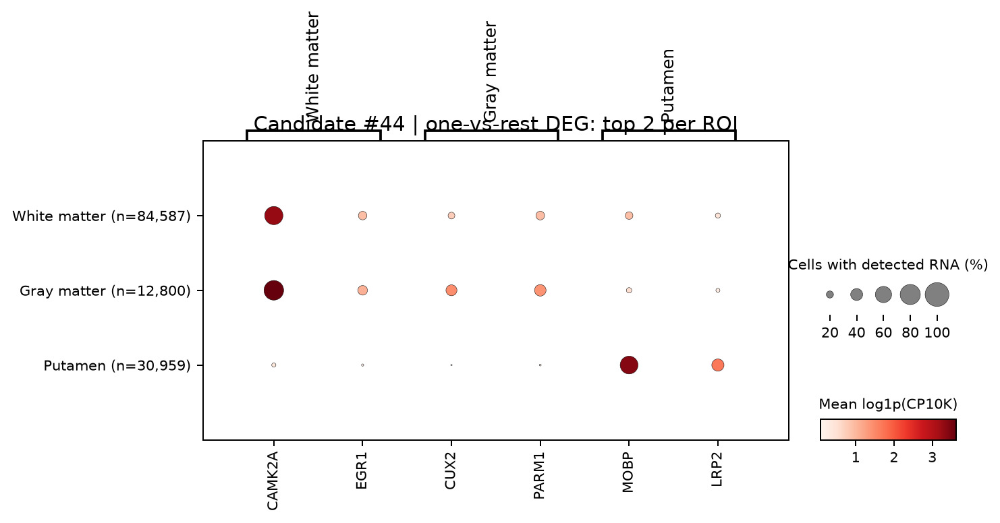


Gray matter: 0 passing candidates / 69 major-ROI, density-supported candidates


,original_rank,n_measurable_markers,n_passing_markers,passing_genes,status
226,92,4,2,"SLC17A7,SYT1",marker_direction_not_supported
10,44,4,1,SLC17A7,marker_direction_not_supported
157,60,4,1,GAD1,marker_direction_not_supported
202,98,4,1,CAMK2A,marker_direction_not_supported
232,83,4,1,CAMK2A,marker_direction_not_supported


현재 조건의 통과 후보 없음. 비교 블록 부족과 마커 방향 미충족은 위 표에서 구분합니다.

Putamen: 0 passing candidates / 7 major-ROI, density-supported candidates


,original_rank,n_measurable_markers,n_passing_markers,passing_genes,status
11,44,0,0,,insufficient_matched_blocks
29,43,0,0,,insufficient_matched_blocks
59,5,0,0,,insufficient_matched_blocks
122,73,0,0,,insufficient_matched_blocks
146,17,0,0,,insufficient_matched_blocks


현재 조건의 통과 후보 없음. 비교 블록 부족과 마커 방향 미충족은 위 표에서 구분합니다.


In [8]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

roi_root = Path.cwd()
if not (roi_root / 'BigBrain_marker_screen').is_dir():
    roi_root = roi_root / 'CCF'
roi_run = max(p.parent for p in (roi_root / 'BigBrain_marker_screen').glob('*/summary.json')
              if json.loads(p.read_text())['n_candidates'] == 100)
roi_audit = pd.read_csv(roi_run / 'candidate_audit.csv')
roi_evidence = pd.read_csv(roi_run / 'marker_evidence.csv')
roi_names = {1: 'White matter', 2: 'Gray matter', 8: 'Putamen'}
roi_rows = []
for candidate in roi_audit.itertuples(index=False):
    major = {int(x) for x in str(candidate.major_region_ids).split(',') if x.isdigit()}
    for roi_id, roi_name in roi_names.items():
        evidence = roi_evidence.loc[(roi_evidence.original_rank == candidate.original_rank)
                                   & (roi_evidence.target_id == roi_id)]
        measurable = evidence['median_detection_delta'].notna()
        positive = measurable & evidence['median_detection_delta'].gt(0)
        passed = positive & evidence['positive_block_share'].ge(0.5)
        n_passed = evidence.loc[passed, 'gene'].nunique()
        n_measurable = evidence.loc[measurable, 'gene'].nunique()
        if roi_id not in major:
            status = 'not_a_major_roi'
        elif not candidate.passes_density_screen:
            status = 'density_screen_failed'
        elif n_passed >= 3:
            status = 'pass'
        elif n_measurable < 3:
            status = 'insufficient_matched_blocks'
        else:
            status = 'marker_direction_not_supported'
        roi_rows.append({'original_rank': candidate.original_rank, 'roi_id': roi_id, 'roi': roi_name,
                         'is_major_roi': roi_id in major, 'passes_density_screen': candidate.passes_density_screen,
                         'fit_score': candidate.fit_score, 'n_measurable_markers': n_measurable,
                         'n_positive_markers': evidence.loc[positive, 'gene'].nunique(),
                         'n_passing_markers': n_passed,
                         'passing_genes': ','.join(evidence.loc[passed, 'gene']), 'status': status})
roi_candidates = pd.DataFrame(roi_rows)
roi_candidates.to_csv(roi_run / 'region_specific_candidate_audit.csv', index=False)
roi_candidates.loc[roi_candidates.status.eq('pass')].to_csv(
    roi_run / 'region_specific_selected_candidates.csv', index=False)
roi_counts = roi_candidates.groupby(['roi', 'status']).size().unstack(fill_value=0)
display(roi_counts.reindex(list(roi_names.values())))
for roi_id, roi_name in roi_names.items():
    relevant = roi_candidates.loc[roi_candidates.roi_id.eq(roi_id) & roi_candidates.is_major_roi
                                  & roi_candidates.passes_density_screen]
    print(f'\n{roi_name}: {relevant.status.eq("pass").sum()} passing candidates / '
          f'{len(relevant)} major-ROI, density-supported candidates')
    display(relevant.sort_values(['n_passing_markers', 'n_measurable_markers', 'fit_score'],
                                ascending=False).head(5)[
        ['original_rank', 'n_measurable_markers', 'n_passing_markers', 'passing_genes', 'status']])
    approved = relevant.loc[relevant.status.eq('pass')]
    for entry in approved.itertuples(index=False):
        print(f'{roi_name} — registration candidate #{entry.original_rank}; supported markers: {entry.passing_genes}')
        for suffix in ('reference_images', 'marker_dotplot'):
            image_path = roi_run / f'candidate_{entry.original_rank}_{suffix}.png'
            if not image_path.is_file():
                raise FileNotFoundError(f'Run the selected candidate plotting cells first: {image_path}')
            display(Image(filename=str(image_path)))
    if approved.empty:
        print('현재 조건의 통과 후보 없음. 비교 블록 부족과 마커 방향 미충족은 위 표에서 구분합니다.')

## 마커 기반 regional mapping 근거 평가: 44번 후보

DEG 상위 유전자 2개를 검증 근거로 재사용하지 않고, 사전에 정한 마커 패널의 발현 방향을 확인합니다. 세포 유형 마커는 해부학적 영역의 전용 마커가 아니므로 이 분석은 조직 구성 일관성을 평가할 뿐 정합 정확도의 확률을 산출하지 않습니다. 후보 선별에도 같은 마커와 절편을 썼으므로 독립 검증이 아닙니다. 전체 ROI one-vs-rest와 공간 블록 내 비교는 모집단·비교 영역이 달라 결과가 다를 수 있으며 한쪽만 골라 신뢰도를 판단하지 않습니다. 블록 비교 불가는 지지/반박이 아니라 근거 부족으로 표시합니다. 세포 수준 p값은 공간적 상관 및 생물학적 반복을 고려하지 못하므로 유의성만으로 신뢰도를 판단하지 않습니다.

,roi,predefined_markers,global_positive_of_4,global_opposite_of_4,block_assessable_of_4,block_positive_of_4,block_comparator
0,White matter,"MOG,CLDN11,MOBP,OPALIN",0,4,4,4,Gray matter
1,Gray matter,"SLC17A7,SYT1,GAD1,CAMK2A",4,0,4,1,White matter
2,Putamen,"PDE10A,ADORA2A,TAC1,PENK",0,4,0,0,Gray matter


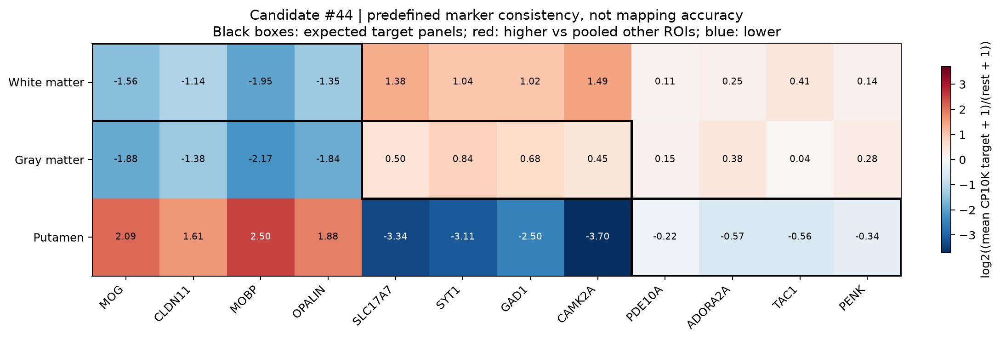

Pooled comparisons and within-block comparisons use different reference populations.
These are marker-consistency diagnostics, not calibrated regional mapping probabilities.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display

assessment_root = Path.cwd()
if not (assessment_root / 'BigBrain_marker_screen').is_dir():
    assessment_root = assessment_root / 'CCF'
assessment_run = max(p.parent for p in (assessment_root / 'BigBrain_marker_screen').glob('*/summary.json')
                     if json.loads(p.read_text())['n_candidates'] == 100)
assessment_deg = pd.read_csv(assessment_run / 'candidate_44_one_vs_rest_DEG.csv')
assessment_spatial = pd.read_csv(assessment_run / 'marker_evidence.csv')
assessment_spatial = assessment_spatial.loc[assessment_spatial.original_rank.eq(44)]
assessment_panels = {1: ('White matter', ['MOG', 'CLDN11', 'MOBP', 'OPALIN']),
                     2: ('Gray matter', ['SLC17A7', 'SYT1', 'GAD1', 'CAMK2A']),
                     8: ('Putamen', ['PDE10A', 'ADORA2A', 'TAC1', 'PENK'])}
assessment_rows, assessment_details = [], []
for roi_id, (name, genes) in assessment_panels.items():
    global_evidence = assessment_deg.loc[assessment_deg.roi_id.eq(roi_id)].set_index('gene').loc[genes].reset_index()
    local_evidence = assessment_spatial.loc[assessment_spatial.target_id.eq(roi_id),
                                          ['gene', 'comparator_id', 'matched_blocks',
                                           'median_detection_delta', 'positive_block_share']]
    detail = global_evidence.merge(local_evidence, on='gene', validate='one_to_one', how='left')
    if len(detail) != 4 or detail['comparator_id'].isna().any():
        raise ValueError(f'{name}: incomplete predefined marker evidence.')
    global_positive = detail.log2fc_target_vs_rest.gt(0) & detail.fraction_target.gt(detail.fraction_rest)
    global_negative = detail.log2fc_target_vs_rest.lt(0) & detail.fraction_target.lt(detail.fraction_rest)
    local_valid = detail.median_detection_delta.notna()
    local_positive = local_valid & detail.median_detection_delta.gt(0) & detail.positive_block_share.ge(0.5)
    assessment_rows.append({'roi': name, 'predefined_markers': ','.join(genes),
                            'global_positive_of_4': int(global_positive.sum()),
                            'global_opposite_of_4': int(global_negative.sum()),
                            'block_assessable_of_4': int(local_valid.sum()),
                            'block_positive_of_4': int(local_positive.sum()),
                            'block_comparator': assessment_panels[int(detail.comparator_id.iloc[0])][0]})
    assessment_details.append(detail)
assessment = pd.DataFrame(assessment_rows)
assessment.to_csv(assessment_run / 'candidate_44_marker_reliability_summary.csv', index=False)
pd.concat(assessment_details, ignore_index=True).to_csv(
    assessment_run / 'candidate_44_marker_reliability_evidence.csv', index=False)
display(assessment)

assessment_genes = [g for _, genes in assessment_panels.values() for g in genes]
heat = assessment_deg.pivot(index='roi_id', columns='gene', values='log2fc_target_vs_rest').loc[
    list(assessment_panels), assessment_genes]
if not np.isfinite(heat.to_numpy()).all():
    raise ValueError('Nonfinite marker effect size in the reliability heatmap.')
limit = max(float(np.abs(heat.to_numpy()).max()), 0.1)
fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
im = ax.imshow(heat, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
for row in range(3):
    ax.add_patch(Rectangle((row * 4 - 0.5, row - 0.5), 4, 1, fill=False, edgecolor='black', linewidth=2))
    for col in range(12):
        ax.text(col, row, f'{heat.iloc[row, col]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(heat.iloc[row, col]) > limit * 0.65 else 'black')
ax.set(xticks=range(12), xticklabels=assessment_genes, yticks=range(3),
       yticklabels=[name for name, _ in assessment_panels.values()],
       title='Candidate #44 | predefined marker consistency, not mapping accuracy\n'
             'Black boxes: expected target panels; red: higher vs pooled other ROIs; blue: lower')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.colorbar(im, ax=ax, label='log2((mean CP10K target + 1)/(rest + 1))', shrink=0.8)
assessment_png = assessment_run / 'candidate_44_marker_reliability.png'
fig.savefig(assessment_png, dpi=180, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(assessment_png)))
print('Pooled comparisons and within-block comparisons use different reference populations.')
print('These are marker-consistency diagnostics, not calibrated regional mapping probabilities.')